# LayerProbe-DF: Audio Deepfake Detection

**Frozen WavLM with Learnable Layer Aggregation**

##  Objective
Detect real and AI-generated audio using pretrained WavLM-Base+ representations.

##  Experiments
1. Layer-wise Probing
2. Learnable Layer Aggregation (LayerAgg)
3. Cross-Dataset Evaluation (FoR)
4. Robustness Testing
5. Explainability and Visualization
6. ASVspoof 2019 LA Evaluation

##  Configuration
- **Model:** `microsoft/wavlm-base-plus`
- **Sample Rate:** 16 kHz
- **Audio Duration:** 4 seconds
- **Feature Shape:** `(13, 768)`
- **Trainable Parameters:** 782

##  Labels
- `0` = Real (Bonafide)
- `1` = Fake (Spoof)

In [ ]:
!pip -q install -U transformers datasets soundfile librosa scikit-learn seaborn
#frozen speech-model inference, and statistical evaluation.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 76.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 49.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 113.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 14.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [ ]:
# Check FFmpeg availability for audio decoding and codec robustness experiments.
!ffmpeg -version | head -n 1

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers


In [ ]:
# Verify the environment.

import importlib
import subprocess

required_packages = [
    "torch",
    "transformers",
    "datasets",
    "soundfile",
    "librosa",
    "sklearn",
    "seaborn",
]

print("Package Verification")
for package in required_packages:
    try:
        module = importlib.import_module(package)
        version = getattr(module, "__version__", "version unavailable")
        print(f"[OK] {package}: {version}")
    except Exception as exc:
        print(f"[ERROR] {package}: {type(exc).__name__}: {exc}")

print("\nFFmpeg Verification")
result = subprocess.run(
    ["ffmpeg", "-version"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print(result.stdout.splitlines()[0])
else:
    print("FFmpeg is unavailable:", result.stderr[:500])

Package Verification
[OK] torch: 2.11.0+cu130
[OK] transformers: 5.20.2
[OK] datasets: 5.1.0
[OK] soundfile: 0.14.0
[OK] librosa: 1.0.0
[OK] sklearn: 1.9.1
[OK] seaborn: 0.13.2

FFmpeg Verification
ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers


In [ ]:
import os
import io
import json
import glob
import random
import subprocess
import tempfile
import warnings

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import librosa
import soundfile as sf
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")

# Reproducibility: seed Python, NumPy, and PyTorch random number generators.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select the available compute device and report the runtime configuration.
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Compute device:", device)
print("PyTorch version:", torch.__version__)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Audio preprocessing configuration.
SR = 16000
CLIP_SEC = 4
CLIP_LEN = SR * CLIP_SEC

# Frozen speech foundation model used for layer-wise feature extraction.
MODEL_NAME = "microsoft/wavlm-base-plus"

# Initial sampling targets
N_TRAIN = 800  # Target total: 400 real + 400 fake training clips
N_TEST = 400   # Target per evaluation set: 200 real + 200 fake clips

# Create directories and containers for experimental artifacts.
os.makedirs("figs", exist_ok=True)
RESULTS = {}

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11
})

print("\nExperiment configuration:")
print(f"Sample rate: {SR} Hz")
print(f"Clip duration: {CLIP_SEC} seconds")
print(f"Target training clips: {N_TRAIN}")
print(f"Target test clips per evaluation set: {N_TEST}")
print(f"Feature extractor: {MODEL_NAME}")
print("Random seed:", SEED)

Compute device: cuda
PyTorch version: 2.11.0+cu130
GPU: Tesla T4

Experiment configuration:
Sample rate: 16000 Hz
Clip duration: 4 seconds
Target training clips: 800
Target test clips per evaluation set: 400
Feature extractor: microsoft/wavlm-base-plus
Random seed: 42


#Evaluation Metrics and Audio Preprocessing Utilities


In [ ]:
def compute_eer(y_true, scores):
    """Estimate equal error rate (EER) from genuine/fake classification scores."""
    y_true = np.asarray(y_true, dtype=np.int32)
    scores = np.asarray(scores, dtype=np.float64)

    if len(np.unique(y_true)) != 2:
        raise ValueError("EER requires both real and fake samples.")
    if not np.isfinite(scores).all():
        raise ValueError("Scores contain NaN or infinite values.")

    fpr, tpr, _ = roc_curve(y_true, scores, pos_label=1)
    fnr = 1.0 - tpr
    idx = np.nanargmin(np.abs(fnr - fpr))

    return float((fpr[idx] + fnr[idx]) / 2.0)


def fix_len(w):
    """Convert an audio waveform to a normalized, fixed-length 4-second clip."""
    w = np.asarray(w, dtype=np.float32).squeeze()

    if w.ndim != 1:
        raise ValueError("Expected a mono, one-dimensional audio waveform.")
    if len(w) == 0:
        raise ValueError("Cannot preprocess an empty audio waveform.")
    if not np.isfinite(w).all():
        raise ValueError("Audio waveform contains NaN or infinite values.")

    if len(w) >= CLIP_LEN:
        start = (len(w) - CLIP_LEN) // 2
        w = w[start:start + CLIP_LEN]
    else:
        # Repeat short clips to avoid introducing artificial zero-only regions.
        w = np.pad(w, (0, CLIP_LEN - len(w)), mode="wrap")

    peak = np.max(np.abs(w))
    if peak > 1e-8:
        w = w / peak * 0.95

    return w.astype(np.float32)


def decode_audio(audio):
    """Decode supported audio representations and resample to the target rate."""
    if isinstance(audio, dict) and "array" in audio:
        # Supports Hugging Face decoded audio examples.
        x = np.asarray(audio["array"], dtype=np.float32)
        sr = int(audio["sampling_rate"])

    else:
        # Supports byte or path audio records.
        if not isinstance(audio, dict):
            raise TypeError("Audio input must be a dictionary.")

        source = (
            io.BytesIO(audio["bytes"])
            if audio.get("bytes") is not None
            else audio.get("path")
        )

        if source is None:
            raise ValueError("Audio record must contain 'array', 'bytes', or 'path'.")

        try:
            x, sr = sf.read(source, dtype="float32")
        except Exception:
            if isinstance(source, io.BytesIO):
                source.seek(0)
            x, sr = librosa.load(source, sr=None, mono=False)
            x = np.asarray(x, dtype=np.float32)

            # librosa with mono=False returns (channels, samples).
            if x.ndim == 2:
                x = x.T

    # Convert stereo or multichannel audio to mono.
    if x.ndim == 2:
        x = x.mean(axis=1)
    elif x.ndim != 1:
        raise ValueError(f"Unsupported audio shape: {x.shape}")

    x = np.asarray(x, dtype=np.float32)

    if not np.isfinite(x).all():
        raise ValueError("Decoded audio contains NaN or infinite values.")

    if sr != SR:
        x = librosa.resample(x, orig_sr=int(sr), target_sr=SR)

    return x.astype(np.float32)


print("Audio preprocessing and evaluation utilities defined successfully.")

Audio preprocessing and evaluation utilities defined successfully.


#Dataset Loading and Label Standardization

In [ ]:
# Supports Hugging Face streaming datasets and local real/fake audio folders.

from datasets import load_dataset, Audio


def inspect_hf(name, split="train", config=None):
    """Inspect dataset features and one example before defining label mappings."""
    ds = load_dataset(name, config, split=split, streaming=True)

    print("Dataset:", name)
    print("Split:", split)
    print("Features:", ds.features)

    try:
        ex = next(iter(ds))
        preview = {
            key: ("<audio data>" if key == "audio" else value)
            for key, value in ex.items()
        }
        print("Example:", preview)
    except StopIteration:
        raise ValueError(f"The requested dataset split is empty: {split}")


def load_hf(
    name,
    split,
    n,
    label_col,
    fake_values,
    config=None,
    audio_col="audio",
):
    """
    Load a balanced sample from a Hugging Face dataset.

    Label convention:
        0 = real (bona fide)
        1 = fake (spoof)

    The label column and fake_values must be verified against the
    dataset's actual schema before loading experimental data.
    """
    if n < 2:
        raise ValueError("Sample size must be at least 2.")
    if n % 2 != 0:
        raise ValueError("Balanced sampling requires an even sample size.")

    ds = load_dataset(name, config, split=split, streaming=True)

    if audio_col not in ds.features:
        raise ValueError(
            f"Audio column '{audio_col}' not found. "
            f"Available columns: {list(ds.features.keys())}"
        )

    if label_col not in ds.features:
        raise ValueError(
            f"Label column '{label_col}' not found. "
            f"Available columns: {list(ds.features.keys())}"
        )

    ds = ds.cast_column(audio_col, Audio(decode=False))
    ds = ds.shuffle(seed=SEED, buffer_size=2000)

    fake_set = {str(value).strip().lower() for value in fake_values}
    half = n // 2
    counts = {0: 0, 1: 0}
    X, y = [], []

    for ex in ds:
        raw_label = str(ex[label_col]).strip().lower()

        # Do not silently classify unknown labels as real.
        if raw_label in fake_set:
            label = 1
        elif raw_label in {"real", "bona fide", "bonafide", "0"}:
            label = 0
        else:
            continue

        if counts[label] >= half:
            continue

        try:
            waveform = fix_len(decode_audio(ex[audio_col]))
        except Exception:
            continue

        X.append(waveform)
        y.append(label)
        counts[label] += 1

        if counts[0] >= half and counts[1] >= half:
            break

    if counts[0] < half or counts[1] < half:
        raise ValueError(
            f"Could not obtain the requested balanced sample from {name}/{split}. "
            f"Collected counts: {counts}; target per class: {half}. "
            "Check dataset labels, split availability, and audio decoding."
        )

    X = np.stack(X).astype(np.float32)
    y = np.asarray(y, dtype=np.int64)

    print(f"Loaded {name}/{split}: X={X.shape}, y={y.shape}")
    print("Class counts (0=real, 1=fake):", {
        int(label): int(count)
        for label, count in zip(*np.unique(y, return_counts=True))
    })

    return X, y


def load_folder(root, n):
    """
    Load a balanced sample from:
        root/real/
        root/fake/

    Each subfolder may contain nested audio files.
    """
    if n < 2 or n % 2 != 0:
        raise ValueError("Balanced sampling requires a positive, even sample size.")

    X, y = [], []
    extensions = (".wav", ".flac", ".mp3", ".ogg")
    half = n // 2

    for label, subfolder in [(0, "real"), (1, "fake")]:
        folder = os.path.join(root, subfolder)

        if not os.path.isdir(folder):
            raise FileNotFoundError(f"Expected dataset folder not found: {folder}")

        files = [
            path for path in glob.glob(
                os.path.join(folder, "**", "*"),
                recursive=True,
            )
            if os.path.isfile(path) and path.lower().endswith(extensions)
        ]

        random.Random(SEED).shuffle(files)

        if len(files) < half:
            raise ValueError(
                f"Insufficient audio files in {folder}: "
                f"found {len(files)}, need {half}."
            )

        for path in files[:half]:
            waveform, _ = librosa.load(path, sr=SR, mono=True)
            X.append(fix_len(waveform))
            y.append(label)

    X = np.stack(X).astype(np.float32)
    y = np.asarray(y, dtype=np.int64)

    print(f"Loaded local dataset from {root}: X={X.shape}, y={y.shape}")
    print("Class counts (0=real, 1=fake):", {
        int(label): int(count)
        for label, count in zip(*np.unique(y, return_counts=True))
    })

    return X, y


def load_source(src, n):
    """Dispatch dataset loading according to the source configuration."""
    if src["kind"] == "hf":
        return load_hf(
            name=src["name"],
            split=src["split"],
            n=n,
            label_col=src["label_col"],
            fake_values=src["fake_values"],
            config=src.get("config"),
            audio_col=src.get("audio_col", "audio"),
        )

    if src["kind"] == "folder":
        return load_folder(src["root"], n)

    raise ValueError(
        f"Unsupported source kind: {src['kind']!r}. "
        "Expected 'hf' or 'folder'."
    )


print("Dataset-loading utilities defined successfully.")

Dataset-loading utilities defined successfully.


#Load Training and Evaluation Datasets

In [ ]:
# Define Dataset Sources
# Replace the placeholders below only after verifying the dataset IDs,
# available splits, audio columns, label columns, and label values.

SRC_A_TRAIN = {
    "kind": "hf",
    "name": "YOUR_VERIFIED_DATASET_A_ID",
    "split": "train",
    "label_col": "YOUR_LABEL_COLUMN",
    "fake_values": ["fake", "spoof", "1"],
    "audio_col": "audio",
}

SRC_A_TEST = {
    "kind": "hf",
    "name": "YOUR_VERIFIED_DATASET_A_ID",
    "split": "test",
    "label_col": "YOUR_LABEL_COLUMN",
    "fake_values": ["fake", "spoof", "1"],
    "audio_col": "audio",
}

SRC_B_TEST = {
    "kind": "hf",
    "name": "YOUR_VERIFIED_DATASET_B_ID",
    "split": "test",
    "label_col": "YOUR_LABEL_COLUMN",
    "fake_values": ["fake", "spoof", "1"],
    "audio_col": "audio",
}

print("Dataset source configurations defined.")
print("Before loading, verify each dataset's actual ID, split, columns, and label mapping.")

Dataset source configurations defined.
Before loading, verify each dataset's actual ID, split, columns, and label mapping.


In [ ]:
# Verified Dataset Source Configuration
# Source: https://huggingface.co/datasets/abdulahh35/ANC-Spoof
# Training: ASVspoof 2019 training split
# In-domain evaluation: ASVspoof 2019 evaluation split
# Cross-domain evaluation: In-the-Wild evaluation split

DATASET_ID = "abdulahh35/ANC-Spoof"

SRC_A_TRAIN = {
    "kind": "hf",
    "name": DATASET_ID,
    "config": "ASVspoof2019",
    "split": "train",
    "label_col": "label",
    "fake_values": ["spoof", "1"],
    "audio_col": "audio",
}

SRC_A_TEST = {
    "kind": "hf",
    "name": DATASET_ID,
    "config": "ASVspoof2019",
    "split": "eval",
    "label_col": "label",
    "fake_values": ["spoof", "1"],
    "audio_col": "audio",
}

SRC_B_TEST = {
    "kind": "hf",
    "name": DATASET_ID,
    "config": "InTheWild",
    "split": "eval",
    "label_col": "label",
    "fake_values": ["spoof", "1"],
    "audio_col": "audio",
}

print("Dataset source configurations defined.")
print("Next: inspect the dataset schemas and verify label mappings before loading samples.")

Dataset source configurations defined.
Next: inspect the dataset schemas and verify label mappings before loading samples.


In [ ]:
# Inspect Verified Dataset Schemas
# Verify actual columns, label encodings, and split availability before loading data.

from datasets import load_dataset

DATASET_ID = "abdulahh35/ANC-Spoof"

for config, split in [
    ("ASVspoof2019", "train"),
    ("ASVspoof2019", "eval"),
    ("InTheWild", "eval"),
]:
    print(f"\n{'=' * 60}")
    print(f"Config: {config} | Split: {split}")

    ds = load_dataset(
        DATASET_ID,
        config,
        split=split,
        streaming=True,
    )

    print("Features:", ds.features)

    # ClassLabel values are encoded as integers; inspect their official mapping.
    label_feature = ds.features.get("label")
    if label_feature is not None and hasattr(label_feature, "names"):
        print("Label mapping:", {
            index: name for index, name in enumerate(label_feature.names)
        })

    example = next(iter(ds))
    print("Example fields:", list(example.keys()))
    print("Example label:", example.get("label"))
    print("Audio metadata:", {
        key: value
        for key, value in example.get("audio", {}).items()
        if key != "bytes" and key != "array"
    })


Config: ASVspoof2019 | Split: train


README.md:   0%|          | 0.00/5.30k [00:00<?, ?B/s]

ValueError: BuilderConfig 'ASVspoof2019' not found. Available: ['default']

In [ ]:
#  Inspect Available Dataset Configurations and Splits
# Discover the repository's actual configuration before attempting to load data.

from datasets import get_dataset_config_names, get_dataset_split_names

DATASET_ID = "abdulahh35/ANC-Spoof"

try:
    configs = get_dataset_config_names(DATASET_ID)
    print("Available configurations:", configs)

    for config in configs:
        try:
            splits = get_dataset_split_names(DATASET_ID, config_name=config)
            print(f"\nConfiguration: {config}")
            print("Available splits:", splits)
        except Exception as exc:
            print(f"Could not inspect splits for {config}: {exc}")

except Exception as exc:
    print(f"Dataset inspection failed: {type(exc).__name__}: {exc}")

Available configurations: ['default']

Configuration: default
Available splits: ['train']


In [ ]:
# Inspect the Available Dataset Split and Label Schema
# The repository exposes only the "default" configuration and "train" split.
# Inspect its actual fields and labels before designing the experimental split.

from datasets import load_dataset

DATASET_ID = "abdulahh35/ANC-Spoof"

ds = load_dataset(
    DATASET_ID,
    split="train",
    streaming=True,
)

print("Dataset features:", ds.features)

label_feature = ds.features.get("label")
if label_feature is not None and hasattr(label_feature, "names"):
    print("Label mapping:", dict(enumerate(label_feature.names)))

print("\nSample records:")
for i, example in enumerate(ds.take(3)):
    preview = {}
    for key, value in example.items():
        if key == "audio" and isinstance(value, dict):
            preview[key] = {
                k: v for k, v in value.items()
                if k not in {"bytes", "array"}
            }
        else:
            preview[key] = value
    print(f"Example {i + 1}:", preview)

Dataset features: {'audio': Audio(sampling_rate=None, decode=True, num_channels=None, stream_index=None), 'label': ClassLabel(names=['fake', 'real'])}
Label mapping: {0: 'fake', 1: 'real'}

Sample records:


ValueError: Invalid string class label ANC-Spoof@70fc8b514372faccab276c46efc387cd41f82d5a

In [ ]:
# Inspect Raw Dataset Records with an Explicit Schema
# Override the repository's inconsistent ClassLabel declaration to inspect
# the underlying label values without automatic integer conversion.

from datasets import load_dataset, Audio, Features, Value

DATASET_ID = "abdulahh35/ANC-Spoof"

raw_features = Features({
    "audio": Audio(decode=False),
    "label": Value("string"),
})

ds = load_dataset(
    DATASET_ID,
    split="train",
    streaming=True,
    features=raw_features,
)

print("Dataset features:", ds.features)
print("Inspecting the first three records...")

for i, example in enumerate(ds.take(3)):
    audio_info = example["audio"]

    print({
        "example": i + 1,
        "raw_label": example["label"],
        "audio_path": audio_info.get("path") if audio_info else None,
        "audio_bytes_available": (
            audio_info.get("bytes") is not None if audio_info else False
        ),
    })

Dataset features: {'audio': Audio(sampling_rate=None, decode=False, num_channels=None, stream_index=None), 'label': Value('string')}
Inspecting the first three records...
{'example': 1, 'raw_label': 'ANC-Spoof@70fc8b514372faccab276c46efc387cd41f82d5a', 'audio_path': 'zip://FoR/BigCodec/fake/file1.wav::hf://datasets/abdulahh35/ANC-Spoof@70fc8b514372faccab276c46efc387cd41f82d5a/FoR.zip', 'audio_bytes_available': False}
{'example': 2, 'raw_label': 'ANC-Spoof@70fc8b514372faccab276c46efc387cd41f82d5a', 'audio_path': 'zip://FoR/BigCodec/fake/file10.wav::hf://datasets/abdulahh35/ANC-Spoof@70fc8b514372faccab276c46efc387cd41f82d5a/FoR.zip', 'audio_bytes_available': False}
{'example': 3, 'raw_label': 'ANC-Spoof@70fc8b514372faccab276c46efc387cd41f82d5a', 'audio_path': 'zip://FoR/BigCodec/fake/file100.wav::hf://datasets/abdulahh35/ANC-Spoof@70fc8b514372faccab276c46efc387cd41f82d5a/FoR.zip', 'audio_bytes_available': False}


In [ ]:
# Inspect Dataset Metadata and Label Structure
# The previous output shows that the "label" field contains repository
# revision identifiers rather than real/fake class labels. Do not train yet.

from huggingface_hub import hf_hub_download
import json

DATASET_ID = "abdulahh35/ANC-Spoof"

readme_path = hf_hub_download(
    repo_id=DATASET_ID,
    filename="README.md",
    repo_type="dataset",
)

with open(readme_path, "r", encoding="utf-8") as f:
    readme = f.read()

print("=== Dataset README ===")
print(readme[:12000])

print("\n=== Dataset repository metadata ===")
from huggingface_hub import HfApi

info = HfApi().dataset_info(DATASET_ID)
print("Repository:", info.id)
print("Revision:", info.sha)
print("Files:")
for item in info.siblings:
    print("-", item.rfilename)

=== Dataset README ===
---
license: cc-by-4.0
task_categories:
- audio-classification
language:
- en
tags:
- audio
- speech
- audio-deepfake-detection
- spoof-detection
- audio-neural-codecs
- codec-compression
pretty_name: 'ANC-Spoof: Audio Neural Codec Spoof Dataset'
size_categories:
- 1M<n<10M
---
# ANC-Spoof: Audio Neural Codec Spoof Dataset

## Overview

**ANC-Spoof (Audio Neural Codec Spoof Dataset)** is a large-scale dataset designed to facilitate research on the robustness of **Audio Deepfake Detection (ADD)** systems against distortions introduced by neural audio codecs.

Neural audio codecs have recently emerged as important components in modern speech technology, serving both as efficient compression mechanisms and as resynthesis components in emerging audio generation systems. The transformations introduced by neural codecs can substantially alter the acoustic characteristics of both bona fide and spoofed speech, potentially affecting the reliability and generalization of e

In [ ]:
# Inspect Dataset Archive Structure
# The repository contains compressed archives rather than directly accessible
# class-labelled records. Inspect the FoR archive to verify its folder structure.

from huggingface_hub import hf_hub_download
import zipfile

DATASET_ID = "abdulahh35/ANC-Spoof"

archive_path = hf_hub_download(
    repo_id=DATASET_ID,
    filename="FoR.zip",
    repo_type="dataset",
)

with zipfile.ZipFile(archive_path, "r") as archive:
    members = archive.namelist()

print("Total archive entries:", len(members))
print("\nFirst 30 archive paths:")
for path in members[:30]:
    print(path)

print("\nTop-level folders:")
top_folders = sorted({
    path.split("/")[0]
    for path in members
    if "/" in path
})
for folder in top_folders:
    print("-", folder)

FoR.zip: reconstructing file:   0%|          |  0.00B / 2.55GB            

FoR.zip: downloading bytes:           |  0.00B            

Total archive entries: 37097

First 30 archive paths:
FoR/
FoR/BigCodec/
FoR/BigCodec/fake/
FoR/BigCodec/fake/file1.wav
FoR/BigCodec/fake/file10.wav
FoR/BigCodec/fake/file100.wav
FoR/BigCodec/fake/file1000.wav
FoR/BigCodec/fake/file1001.wav
FoR/BigCodec/fake/file1002.wav
FoR/BigCodec/fake/file1003.wav
FoR/BigCodec/fake/file1004.wav
FoR/BigCodec/fake/file1005.wav
FoR/BigCodec/fake/file1006.wav
FoR/BigCodec/fake/file1007.wav
FoR/BigCodec/fake/file1008.wav
FoR/BigCodec/fake/file1009.wav
FoR/BigCodec/fake/file101.wav
FoR/BigCodec/fake/file1010.wav
FoR/BigCodec/fake/file1011.wav
FoR/BigCodec/fake/file1012.wav
FoR/BigCodec/fake/file1013.wav
FoR/BigCodec/fake/file1014.wav
FoR/BigCodec/fake/file1015.wav
FoR/BigCodec/fake/file1016.wav
FoR/BigCodec/fake/file1017.wav
FoR/BigCodec/fake/file1018.wav
FoR/BigCodec/fake/file1019.wav
FoR/BigCodec/fake/file102.wav
FoR/BigCodec/fake/file1020.wav
FoR/BigCodec/fake/file1021.wav

Top-level folders:
- FoR


In [ ]:
# Verify Real/Fake Labels and Codec Directory Structure

from collections import Counter

with zipfile.ZipFile(archive_path, "r") as archive:
    members = archive.namelist()

counts = Counter()
codecs = set()

for path in members:
    parts = path.strip("/").split("/")
    if len(parts) >= 4 and parts[0] == "FoR":
        codec, label = parts[1], parts[2]
        if label in {"real", "fake"} and path.lower().endswith(".wav"):
            counts[(codec, label)] += 1
            codecs.add(codec)

print("Available codec directories:", sorted(codecs))
print("\nAudio file counts by codec and class:")

for codec in sorted(codecs):
    print(
        f"{codec}: "
        f"fake={counts[(codec, 'fake')]:,}, "
        f"real={counts[(codec, 'real')]:,}"
    )

print("\nOriginal audio present:", "Original" in codecs)

Available codec directories: ['BigCodec', 'DAC', 'HiggsAudioV2', 'Mimi', 'Original', 'SNAC', 'SpeechTokenizer', 'WavTokenizer']

Audio file counts by codec and class:
BigCodec: fake=2,370, real=2,264
DAC: fake=2,370, real=2,264
HiggsAudioV2: fake=2,370, real=2,264
Mimi: fake=2,370, real=2,264
Original: fake=2,370, real=2,264
SNAC: fake=2,370, real=2,264
SpeechTokenizer: fake=2,370, real=2,264
WavTokenizer: fake=2,370, real=2,264

Original audio present: True


In [ ]:
# Define Verified FoR Dataset Source
# Use the Original directory to avoid mixing codec variants of the same utterance.
# Labels are derived from verified archive paths: real=0, fake=1.

SRC_A_TRAIN = {
    "kind": "folder",
    "root": "/content/ANC-Spoof/FoR/Original",
}

SRC_A_TEST = {
    "kind": "folder",
    "root": "/content/ANC-Spoof/FoR/Original",
}

SRC_B_TEST = {
    "kind": "folder",
    "root": "/content/ANC-Spoof/FoR/Original",
}

print("FoR archive structure verified.")
print("Warning: the archive is not extracted to these paths yet.")
print("Training and test sources must be separated before evaluation.")

FoR archive structure verified.
Training and test sources must be separated before evaluation.


## Frozen WavLM Embeddings

We extract mean-pooled hidden-state representations from all 13 layers of a frozen WavLM-Base+ model. The model remains frozen throughout the experiment, with no fine-tuning. For each layer, we average the hidden states across the time dimension to obtain a fixed-size representation for each audio clip.

In [ ]:
# Frozen WavLM embeddings from all 13 hidden-state outputs

from transformers import AutoFeatureExtractor, WavLMModel
import numpy as np
import torch

fe = AutoFeatureExtractor.from_pretrained(MODEL_NAME)
wavlm = WavLMModel.from_pretrained(MODEL_NAME).to(device).eval()

for p in wavlm.parameters():
    p.requires_grad = False

print("Frozen backbone parameters:", sum(p.numel() for p in wavlm.parameters()))

@torch.no_grad()
def embed(waves, bs=8):
    out = []

    for i in range(0, len(waves), bs):
        batch = [np.asarray(w, dtype=np.float32) for w in waves[i:i + bs]]

        inp = fe(
            batch,
            sampling_rate=SR,
            return_tensors="pt",
            padding=True
        )
        input_values = inp.input_values.to(device)

        hidden_states = wavlm(
            input_values,
            output_hidden_states=True
        ).hidden_states

        # Exclude the embedding output; retain the 12 Transformer layers
        # plus the initial embedding representation = 13 representations.
        H = torch.stack(hidden_states, dim=1)  # (B, 13, T, 768)

        # Mean-pool over the time dimension.
        H = H.mean(dim=2)  # (B, 13, 768)

        out.append(H.cpu().numpy())

    if not out:
        raise ValueError("No waveforms provided for embedding extraction.")

    return np.concatenate(out, axis=0).astype(np.float32)


Etr = embed(Xtr_w)
EA = embed(XA_w)
EB = embed(XB_w)

print("Training embeddings:", Etr.shape)
print("In-domain test embeddings:", EA.shape)
print("Cross-dataset test embeddings:", EB.shape)

assert Etr.ndim == EA.ndim == EB.ndim == 3
assert Etr.shape[1:] == EA.shape[1:] == EB.shape[1:] == (13, 768)
assert np.isfinite(Etr).all() and np.isfinite(EA).all() and np.isfinite(EB).all()

print("Embedding extraction verified.")

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Frozen backbone parameters: 94381936


NameError: name 'Xtr_w' is not defined

In [ ]:
# Check whether the waveform variables have been created
for name in ["Xtr_w", "XA_w", "XB_w", "X_train", "X_test"]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: shape={getattr(value, 'shape', 'not available')}, "
              f"type={type(value).__name__}")
    else:
        print(f"{name}: NOT DEFINED")

Xtr_w: NOT DEFINED
XA_w: NOT DEFINED
XB_w: NOT DEFINED
X_train: NOT DEFINED
X_test: NOT DEFINED


In [ ]:
# Inspect available dataset variables without modifying anything
for name, value in list(globals().items()):
    if name.startswith(("X", "y", "SRC_")):
        if not name.startswith("_"):
            shape = getattr(value, "shape", None)
            length = len(value) if hasattr(value, "__len__") else None
            print(f"{name}: type={type(value).__name__}, shape={shape}, length={length}")

SRC_A_TRAIN: type=dict, shape=None, length=2
SRC_A_TEST: type=dict, shape=None, length=2
SRC_B_TEST: type=dict, shape=None, length=2


In [ ]:
# Inspect configured dataset sources
for name in ["SRC_A_TRAIN", "SRC_A_TEST", "SRC_B_TEST"]:
    print(f"\n{name}")
    for key, value in globals()[name].items():
        print(f"  {key}: {value}")


SRC_A_TRAIN
  kind: folder
  root: /content/ANC-Spoof/FoR/Original

SRC_A_TEST
  kind: folder
  root: /content/ANC-Spoof/FoR/Original

SRC_B_TEST
  kind: folder
  root: /content/ANC-Spoof/FoR/Original


In [ ]:
# Verify archive and extracted dataset locations
from pathlib import Path

paths = [
    Path("/content/ANC-Spoof"),
    Path("/content/ANC-Spoof/FoR/Original"),
    Path("/content/ANC-Spoof/FoR/Original/real"),
    Path("/content/ANC-Spoof/FoR/Original/fake"),
]

for path in paths:
    print(f"{path}: {'EXISTS' if path.exists() else 'NOT FOUND'}")

print("\nPossible extracted FoR directories:")
for path in Path("/content").glob("**/FoR/Original"):
    print(path)

/content/ANC-Spoof: NOT FOUND
/content/ANC-Spoof/FoR/Original: NOT FOUND
/content/ANC-Spoof/FoR/Original/real: NOT FOUND
/content/ANC-Spoof/FoR/Original/fake: NOT FOUND

Possible extracted FoR directories:


In [ ]:
# Locate the downloaded FoR archive in the Hugging Face cache
from pathlib import Path
import os

roots = [
    Path("/root/.cache/huggingface/hub"),
    Path("/content"),
]

found = []

for root in roots:
    if root.exists():
        for path in root.rglob("FoR.zip"):
            found.append(path)
            print(f"Found: {path}")
            print(f"Size: {path.stat().st_size / (1024**3):.2f} GB")

if not found:
    print("FoR.zip not found in the checked locations.")
    print("The archive may need to be downloaded again.")

Found: /root/.cache/huggingface/hub/datasets--abdulahh35--ANC-Spoof/snapshots/70fc8b514372faccab276c46efc387cd41f82d5a/FoR.zip
Size: 2.37 GB


In [ ]:
# Inspect the FoR archive without extracting its 2.37 GB contents
from zipfile import ZipFile
from pathlib import Path
from collections import Counter

FOR_ZIP = Path(
    "/root/.cache/huggingface/hub/datasets--abdulahh35--ANC-Spoof/"
    "snapshots/70fc8b514372faccab276c46efc387cd41f82d5a/FoR.zip"
)

with ZipFile(FOR_ZIP, "r") as zf:
    names = [
        name for name in zf.namelist()
        if not name.endswith("/")
    ]

    original = [
        name for name in names
        if name.startswith("FoR/Original/")
        and name.lower().endswith(".wav")
    ]

    counts = Counter()
    for name in original:
        parts = Path(name).parts
        if len(parts) >= 4 and parts[2] in ("real", "fake"):
            counts[parts[2]] += 1

    print("Archive exists:", FOR_ZIP.exists())
    print("Original WAV files:", len(original))
    print("Original class counts:", dict(counts))
    print("Example paths:")
    for name in original[:5]:
        print(" ", name)

Archive exists: True
Original WAV files: 4634
Original class counts: {'fake': 2370, 'real': 2264}
Example paths:
  FoR/Original/fake/file1.wav
  FoR/Original/fake/file10.wav
  FoR/Original/fake/file100.wav
  FoR/Original/fake/file1000.wav
  FoR/Original/fake/file1001.wav


In [ ]:
# Extract and Verify FoR Original Audio
from pathlib import Path
from zipfile import ZipFile

FOR_ZIP = Path(
    "/root/.cache/huggingface/hub/datasets--abdulahh35--ANC-Spoof/"
    "snapshots/70fc8b514372faccab276c46efc387cd41f82d5a/FoR.zip"
)

FOR_ROOT = Path("/content/ANC-Spoof/FoR/Original")

assert FOR_ZIP.exists(), f"Archive not found: {FOR_ZIP}"

# Extract only original FoR audio files
with ZipFile(FOR_ZIP, "r") as zf:
    members = [
        name for name in zf.namelist()
        if name.startswith("FoR/Original/")
        and not name.endswith("/")
        and name.lower().endswith(".wav")
    ]

    for member in members:
        zf.extract(member, "/content/ANC-Spoof")

real_files = list((FOR_ROOT / "real").glob("*.wav"))
fake_files = list((FOR_ROOT / "fake").glob("*.wav"))

print("FoR extraction complete.")
print("Real files:", len(real_files))
print("Fake files:", len(fake_files))
print("Total files:", len(real_files) + len(fake_files))

assert len(real_files) == 2264, f"Unexpected real count: {len(real_files)}"
assert len(fake_files) == 2370, f"Unexpected fake count: {len(fake_files)}"

print("Verification passed.")

FoR extraction complete.
Real files: 2264
Fake files: 2370
Total files: 4634
Verification passed.


#Model + Embedding Extractor

In [ ]:

from transformers import AutoFeatureExtractor, WavLMModel
import numpy as np
import torch

fe = AutoFeatureExtractor.from_pretrained(MODEL_NAME)
wavlm = WavLMModel.from_pretrained(MODEL_NAME).to(device).eval()

for p in wavlm.parameters():
    p.requires_grad = False

print("Frozen backbone params:", sum(p.numel() for p in wavlm.parameters()))

@torch.no_grad()
def embed(waves, bs=8):
    if len(waves) == 0:
        raise ValueError("No waveforms provided.")

    out = []

    for i in range(0, len(waves), bs):
        batch = [
            np.asarray(w, dtype=np.float32).reshape(-1)
            for w in waves[i:i + bs]
        ]

        inp = fe(
            batch,
            sampling_rate=SR,
            return_tensors="pt",
            padding=True
        )

        hs = wavlm(
            inp.input_values.to(device),
            output_hidden_states=True
        ).hidden_states

        # 13 representations: embedding output + 12 Transformer layers
        H = torch.stack(hs, dim=1).mean(dim=2)  # (B, 13, 768)
        out.append(H.cpu().numpy())

    return np.concatenate(out, axis=0).astype(np.float32)

print("Embedding extractor ready.")
print("Expected shape per audio:", (13, 768))

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

Frozen backbone params: 94381936
Embedding extractor ready.
Expected shape per audio: (13, 768)


In [ ]:
#Load FoR Original Audio as Cross-Dataset Test Data

from pathlib import Path
import numpy as np
import soundfile as sf

FOR_ROOT = Path("/content/ANC-Spoof/FoR/Original")

def load_for_original(root, max_per_class=200):
    waves, labels = [], []

    for folder, label in [("real", 0), ("fake", 1)]:
        files = sorted((root / folder).glob("*.wav"))
        if not files:
            raise FileNotFoundError(f"No WAV files found in {root / folder}")

        # Reproducible sampling for a manageable first experiment
        rng = np.random.default_rng(SEED + label)
        selected = rng.choice(
            len(files),
            size=min(max_per_class, len(files)),
            replace=False
        )

        for i in selected:
            audio, sr = sf.read(files[int(i)], dtype="float32")
            audio = decode_audio({"array": audio, "sampling_rate": sr})
            waves.append(fix_len(audio))
            labels.append(label)

    order = np.random.default_rng(SEED).permutation(len(labels))
    waves = [waves[i] for i in order]
    labels = np.asarray(labels, dtype=np.int64)[order]

    return waves, labels

XB_w, yB = load_for_original(FOR_ROOT, max_per_class=200)

print("FoR test waveforms:", len(XB_w))
print("FoR labels:", dict(zip(*np.unique(yB, return_counts=True))))
print("Waveform shape:", XB_w[0].shape)

FoR test waveforms: 400
FoR labels: {np.int64(0): np.int64(200), np.int64(1): np.int64(200)}
Waveform shape: (64000,)


In [ ]:
# Check ASVspoof2019 archive availability

from pathlib import Path

snapshot = Path(
    "/root/.cache/huggingface/hub/datasets--abdulahh35--ANC-Spoof/"
    "snapshots/70fc8b514372faccab276c46efc387cd41f82d5a"
)

if not snapshot.exists():
    print("ANC-Spoof snapshot not found.")
else:
    for path in sorted(snapshot.glob("ASVspoof2019.7z.*")):
        print(f"{path.name}: {path.stat().st_size / (1024**2):.1f} MB")

    print("Archive parts found:", len(list(snapshot.glob("ASVspoof2019.7z.*"))))

Archive parts found: 0


In [ ]:
# Inspect available ANC-Spoof files
from pathlib import Path

snapshot = Path(
    "/root/.cache/huggingface/hub/datasets--abdulahh35--ANC-Spoof/"
    "snapshots/70fc8b514372faccab276c46efc387cd41f82d5a"
)

if snapshot.exists():
    for path in sorted(snapshot.iterdir()):
        print(path.name, f"({path.stat().st_size / (1024**2):.1f} MB)" if path.is_file() else "[directory]")
else:
    print("Snapshot directory not found.")

FoR.zip (2430.9 MB)
README.md (0.0 MB)


In [ ]:
# Inspect ANC-Spoof README for official dataset sources

from pathlib import Path

readme_path = Path(
    "/root/.cache/huggingface/hub/datasets--abdulahh35--ANC-Spoof/"
    "snapshots/70fc8b514372faccab276c46efc387cd41f82d5a/README.md"
)

text = readme_path.read_text(errors="replace")
print(text[:15000])

---
license: cc-by-4.0
task_categories:
- audio-classification
language:
- en
tags:
- audio
- speech
- audio-deepfake-detection
- spoof-detection
- audio-neural-codecs
- codec-compression
pretty_name: 'ANC-Spoof: Audio Neural Codec Spoof Dataset'
size_categories:
- 1M<n<10M
---
# ANC-Spoof: Audio Neural Codec Spoof Dataset

## Overview

**ANC-Spoof (Audio Neural Codec Spoof Dataset)** is a large-scale dataset designed to facilitate research on the robustness of **Audio Deepfake Detection (ADD)** systems against distortions introduced by neural audio codecs.

Neural audio codecs have recently emerged as important components in modern speech technology, serving both as efficient compression mechanisms and as resynthesis components in emerging audio generation systems. The transformations introduced by neural codecs can substantially alter the acoustic characteristics of both bona fide and spoofed speech, potentially affecting the reliability and generalization of existing audio deepfake 

In [ ]:
# Verify ASVspoof archive files in the Hugging Face repository

from huggingface_hub import HfApi

api = HfApi()
repo_id = "abdulahh35/ANC-Spoof"

files = api.list_repo_files(repo_id, repo_type="dataset")

asv_files = [
    name for name in files
    if "ASVspoof2019" in name
]

print("ASVspoof-related files:", len(asv_files))
for name in asv_files[:30]:
    print(name)

ASVspoof-related files: 11
ASVspoof2019.7z.001
ASVspoof2019.7z.002
ASVspoof2019.7z.003
ASVspoof2019.7z.004
ASVspoof2019.7z.005
ASVspoof2019.7z.006
ASVspoof2019.7z.007
ASVspoof2019.7z.008
ASVspoof2019.7z.009
ASVspoof2019.7z.010
ASVspoof2019.7z.011


In [ ]:
# Download ASVspoof2019 archive parts
from pathlib import Path
from huggingface_hub import hf_hub_download

REPO_ID = "abdulahh35/ANC-Spoof"
ASV_DIR = Path("/content/ASVspoof2019_archives")
ASV_DIR.mkdir(parents=True, exist_ok=True)

archive_parts = [
    f"ASVspoof2019.7z.{i:03d}"
    for i in range(1, 12)
]

downloaded_parts = []

for filename in archive_parts:
    path = hf_hub_download(
        repo_id=REPO_ID,
        repo_type="dataset",
        filename=filename,
        local_dir=str(ASV_DIR),
    )
    downloaded_parts.append(Path(path))
    print(f"Available: {filename}")

print("\nParts found:", len(downloaded_parts))
print("Total size (GB):", round(
    sum(p.stat().st_size for p in downloaded_parts) / (1024**3), 2
))

assert len(downloaded_parts) == 11
assert all(p.exists() and p.stat().st_size > 0 for p in downloaded_parts)

print("All ASVspoof archive parts verified.")

ASVspoof2019.7z.001: reconstructing file:   0%|          |  0.00B / 5.37GB            

ASVspoof2019.7z.001: downloading bytes:           |  0.00B            

Available: ASVspoof2019.7z.001


ASVspoof2019.7z.002: reconstructing file:   0%|          |  0.00B / 5.37GB            

ASVspoof2019.7z.002: downloading bytes:           |  0.00B            

...

ASVspoof2019.7z.010: downloading bytes:           |  0.00B            

Available: ASVspoof2019.7z.010


ASVspoof2019.7z.011: reconstructing file:   0%|          |  0.00B / 4.20GB            

ASVspoof2019.7z.011: downloading bytes:           |  0.00B            

Available: ASVspoof2019.7z.011

Parts found: 11
Total size (GB): 53.92
All ASVspoof archive parts verified.


In [ ]:
# Check disk space and prepare 7z extraction tool
import shutil
import subprocess

disk = shutil.disk_usage("/content")

print(f"Total disk: {disk.total / (1024**3):.2f} GB")
print(f"Used disk: {disk.used / (1024**3):.2f} GB")
print(f"Free disk: {disk.free / (1024**3):.2f} GB")

if shutil.which("7z") is None:
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "p7zip-full"],
        check=True
    )

print("\n7z available:", shutil.which("7z"))

Total disk: 112.64 GB
Used disk: 100.22 GB
Free disk: 12.40 GB

7z available: /usr/bin/7z


In [ ]:
# Inspect the multi-part archive without extracting it
from pathlib import Path
import subprocess

ASV_DIR = Path("/content/ASVspoof2019_archives")
archive = ASV_DIR / "ASVspoof2019.7z.001"

result = subprocess.run(
    ["7z", "l", str(archive)],
    capture_output=True,
    text=True,
    timeout=300
)

print("Return code:", result.returncode)
print(result.stdout[-12000:])

if result.returncode != 0:
    print("Archive listing error:")
    print(result.stderr[-3000:])

Return code: 0
T_9964492.flac
2026-07-11 04:31:21 ....A        49770               ASVspoof2019/WavTokenizer/ASVspoof2019_LA_train/flac/LA_T_9964543.flac
2026-07-11 04:31:21 ....A        87918               ASVspoof2019/WavTokenizer/ASVspoof2019_LA_train/flac/LA_T_9965240.flac
2026-07-11 04:31:21 ....A        31967               ASVspoof2019/WavTokenizer/ASVspoof2019_LA_train/flac/LA_T_9965999.flac
2026-07-11 04:31:21 ....A        40516               ASVspoof2019/WavTokenizer/ASVspoof2019_LA_train/flac/LA_T_9966135.flac
2026-07-11 04:31:21 ....A        37578               ASVspoof2019/WavTokenizer/ASVspoof2019_LA_train/flac/LA_T_9966635.flac
2026-07-11 04:31:21 ....A        36737               ASVspoof2019/WavTokenizer/ASVspoof2019_LA_train/flac/LA_T_9967437.flac
2026-07-11 04:31:21 ....A        40286               ASVspoof2019/WavTokenizer/ASVspoof2019_LA_train/flac/LA_T_9967617.flac
2026-07-11 04:31:21 ....A        38702               ASVspoof2019/WavTokenizer/ASVspoof2019_LA_train/f

In [ ]:
# Inspect Original audio and protocol files inside the archive
import subprocess
from pathlib import Path

archive = Path("/content/ASVspoof2019_archives/ASVspoof2019.7z.001")

result = subprocess.run(
    ["7z", "l", str(archive), "ASVspoof2019/Original/*"],
    capture_output=True,
    text=True,
    timeout=300
)

print("Return code:", result.returncode)

if result.returncode == 0:
    lines = result.stdout.splitlines()
    relevant = [
        line for line in lines
        if any(term in line.lower() for term in [
            "la_train", "la_dev", "la_eval",
            "protocol", "metadata"
        ])
    ]

    print("\nRelevant archive entries:")
    for line in relevant[:50]:
        print(line)

    print("\nMatching entries shown:", min(len(relevant), 50))
else:
    print(result.stderr[-3000:])

Return code: 0

Relevant archive entries:
2026-07-28 17:31:21 D....            0            0  ASVspoof2019/Original/ASVspoof2019_LA_asv_protocols
2026-07-28 17:31:21 D....            0            0  ASVspoof2019/Original/ASVspoof2019_LA_cm_protocols
2026-07-28 17:31:22 D....            0            0  ASVspoof2019/Original/ASVspoof2019_LA_dev
2026-07-28 17:32:50 D....            0            0  ASVspoof2019/Original/ASVspoof2019_LA_dev/flac
2026-07-28 17:32:55 D....            0            0  ASVspoof2019/Original/ASVspoof2019_LA_eval
2026-07-28 17:39:48 D....            0            0  ASVspoof2019/Original/ASVspoof2019_LA_eval/flac
2026-07-28 17:39:49 D....            0            0  ASVspoof2019/Original/ASVspoof2019_LA_train
2026-07-28 17:42:03 D....            0            0  ASVspoof2019/Original/ASVspoof2019_LA_train/flac
2023-09-19 16:50:36 ....A       677652               ASVspoof2019/Original/ASVspoof2019_LA_asv_protocols/ASVspoof2019.LA.asv.dev.female.trl.txt
2023-09-19 16:

In [ ]:
# Inspect ASVspoof2019 protocol and metadata files
import subprocess
from pathlib import Path

archive = "/content/ASVspoof2019_archives/ASVspoof2019.7z.001"

result = subprocess.run(
    ["7z", "l", str(archive), "ASVspoof2019/Original/*protocol*"],
    capture_output=True,
    text=True,
    timeout=300
)

print("Return code:", result.returncode)
print(result.stdout[-12000:] if result.returncode == 0 else result.stderr[-3000:])

Return code: 0

7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
1 file, 5368709120 bytes (5120 MiB)

Listing archive: /content/ASVspoof2019_archives/ASVspoof2019.7z.001

--
Path = /content/ASVspoof2019_archives/ASVspoof2019.7z.001
Type = Split
Physical Size = 5368709120
Volumes = 11
Total Physical Size = 57890896349
----
Path = ASVspoof2019.7z
Size = 57890896349
--
Path = ASVspoof2019.7z
Type = 7z
Physical Size = 57890896349
Headers Size = 10726791
Method = LZMA2:25
Solid = +
Blocks = 7

   Date      Time    Attr         Size   Compressed  Name
------------------- ----- ------------ ------------  ------------------------
2026-07-28 17:31:21 D....            0            0  ASVspoof2019/Original/ASVspoof2019_LA_asv_protocols
2026-07-28 17:31:21 D....            0            0  ASVspoof2019/Original/ASVspoof2019_LA_cm_protocols
2023-09-19 16:50:36 ....A       677652               

In [ ]:
# Extract only ASVspoof training and validation protocol files
import subprocess
from pathlib import Path

archive = "/content/ASVspoof2019_archives/ASVspoof2019.7z.001"
out_dir = "/content/asvspoof_protocols"

Path(out_dir).mkdir(parents=True, exist_ok=True)

targets = [
    "ASVspoof2019/Original/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt",
    "ASVspoof2019/Original/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.dev.trl.txt",
]

for target in targets:
    result = subprocess.run(
        ["7z", "e", "-y", f"-o{out_dir}", archive, target],
        capture_output=True,
        text=True,
        timeout=600
    )
    print(f"\nFile: {Path(target).name}")
    print("Return code:", result.returncode)
    if result.returncode != 0:
        print(result.stderr[-2000:])

print("\nExtracted files:")
for p in Path(out_dir).glob("*.txt"):
    print(p.name, "|", f"{p.stat().st_size:,} bytes")


File: ASVspoof2019.LA.cm.train.trn.txt
Return code: 0

File: ASVspoof2019.LA.cm.dev.trl.txt
Return code: 0

Extracted files:
ASVspoof2019.LA.cm.dev.trl.txt | 822,400 bytes
ASVspoof2019.LA.cm.train.trn.txt | 840,120 bytes


In [ ]:
# Inspect ASVspoof protocol format and labels
from pathlib import Path
from collections import Counter

protocol_dir = Path("/content/asvspoof_protocols")

train_file = protocol_dir / "ASVspoof2019.LA.cm.train.trn.txt"
dev_file = protocol_dir / "ASVspoof2019.LA.cm.dev.trl.txt"

for name, path in [("TRAIN", train_file), ("DEV", dev_file)]:
    print(f"\n{'='*20} {name} {'='*20}")

    with open(path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    print("Total entries:", len(lines))
    print("First 5 entries:")
    for line in lines[:5]:
        print(line)

    labels = Counter(line.split()[-1] for line in lines)
    print("Label counts:", labels)


==================== TRAIN ====================
Total entries: 25380
First 5 entries:
LA_0079 LA_T_1138215 - - bonafide
LA_0079 LA_T_1271820 - - bonafide
LA_0079 LA_T_1272637 - - bonafide
LA_0079 LA_T_1276960 - - bonafide
LA_0079 LA_T_1341447 - - bonafide
Label counts: Counter({'spoof': 22800, 'bonafide': 2580})

==================== DEV ====================
Total entries: 24844
First 5 entries:
LA_0069 LA_D_1047731 - - bonafide
LA_0069 LA_D_1105538 - - bonafide
LA_0069 LA_D_1125976 - - bonafide
LA_0069 LA_D_1293230 - - bonafide
LA_0069 LA_D_1340209 - - bonafide
Label counts: Counter({'spoof': 22296, 'bonafide': 2548})


In [ ]:
# Select balanced ASVspoof train/dev samples and verify audio paths
from pathlib import Path
import random
from collections import Counter

random.seed(SEED)

protocol_dir = Path("/content/asvspoof_protocols")
archive_prefix = "ASVspoof2019/Original"

train_file = protocol_dir / "ASVspoof2019.LA.cm.train.trn.txt"
dev_file = protocol_dir / "ASVspoof2019.LA.cm.dev.trl.txt"

def read_protocol(path, split, n_per_class):
    rows = []
    with open(path, "r") as f:
        for line in f:
            parts = line.split()
            if len(parts) < 5:
                continue
            speaker, utt_id, label = parts[0], parts[1], parts[-1]
            if label in ("bonafide", "spoof"):
                rows.append({
                    "utt_id": utt_id,
                    "label": 0 if label == "bonafide" else 1,
                    "split": split,
                    "path": f"{archive_prefix}/ASVspoof2019_LA_{split}/flac/{utt_id}.flac"
                })

    selected = []
    for label in (0, 1):
        candidates = [r for r in rows if r["label"] == label]
        selected.extend(random.sample(candidates, min(n_per_class, len(candidates))))

    random.shuffle(selected)
    return selected

train_rows = read_protocol(train_file, "train", 400)
dev_rows = read_protocol(dev_file, "dev", 200)

print("Selected train:", len(train_rows), Counter(r["label"] for r in train_rows))
print("Selected dev:", len(dev_rows), Counter(r["label"] for r in dev_rows))
print("\nExample train entries:")
for r in train_rows[:5]:
    print(r)

Selected train: 800 Counter({1: 400, 0: 400})
Selected dev: 400 Counter({0: 200, 1: 200})

Example train entries:
{'utt_id': 'LA_T_3618704', 'label': 1, 'split': 'train', 'path': 'ASVspoof2019/Original/ASVspoof2019_LA_train/flac/LA_T_3618704.flac'}
{'utt_id': 'LA_T_8257553', 'label': 0, 'split': 'train', 'path': 'ASVspoof2019/Original/ASVspoof2019_LA_train/flac/LA_T_8257553.flac'}
{'utt_id': 'LA_T_7826803', 'label': 0, 'split': 'train', 'path': 'ASVspoof2019/Original/ASVspoof2019_LA_train/flac/LA_T_7826803.flac'}
{'utt_id': 'LA_T_7388290', 'label': 1, 'split': 'train', 'path': 'ASVspoof2019/Original/ASVspoof2019_LA_train/flac/LA_T_7388290.flac'}
{'utt_id': 'LA_T_6861216', 'label': 0, 'split': 'train', 'path': 'ASVspoof2019/Original/ASVspoof2019_LA_train/flac/LA_T_6861216.flac'}


In [ ]:
# Extract only selected ASVspoof train/dev audio files
import subprocess
from pathlib import Path

archive = "/content/ASVspoof2019_archives/ASVspoof2019.7z.001"
out_dir = Path("/content/asvspoof_selected")
out_dir.mkdir(parents=True, exist_ok=True)

targets = [r["path"] for r in train_rows + dev_rows]

# Extract selected files in batches to avoid an oversized command
batch_size = 100
failed = []

for start in range(0, len(targets), batch_size):
    batch = targets[start:start + batch_size]
    result = subprocess.run(
        ["7z", "x", "-y", f"-o{out_dir}", archive, *batch],
        capture_output=True,
        text=True,
        timeout=1800
    )

    if result.returncode != 0:
        failed.extend(batch)
        print(f"Batch {start // batch_size + 1} failed:")
        print(result.stderr[-1000:])

    print(f"Processed {min(start + batch_size, len(targets))}/{len(targets)}")

# Build a mapping from utterance ID to extracted audio path
audio_root = out_dir / "ASVspoof2019" / "Original"
audio_map = {
    p.stem: p
    for p in audio_root.rglob("*.flac")
}

missing = [r["utt_id"] for r in train_rows + dev_rows if r["utt_id"] not in audio_map]

print("\nExtracted FLAC files:", len(audio_map))
print("Missing selected files:", len(missing))
print("Failed batches:", len(failed))
print("Example missing IDs:", missing[:10])

Processed 100/1200
Processed 200/1200
Processed 300/1200
Processed 400/1200
Processed 500/1200
Processed 600/1200
Processed 700/1200
Processed 800/1200
Processed 900/1200
Processed 1000/1200
Processed 1100/1200
Processed 1200/1200

Extracted FLAC files: 1200
Missing selected files: 0
Failed batches: 0
Example missing IDs: []


In [ ]:
# Load selected ASVspoof train/dev waveforms
import numpy as np
import soundfile as sf
import librosa
from pathlib import Path
from collections import Counter
from tqdm.auto import tqdm

audio_root = Path("/content/asvspoof_selected/ASVspoof2019/Original")

def load_asvspoof_rows(rows, audio_map):
    waves, labels, missing = [], [], []

    for row in tqdm(rows, desc=f"Loading {rows[0]['split']} audio"):
        path = audio_map.get(row["utt_id"])

        if path is None or not path.exists():
            missing.append(row["utt_id"])
            continue

        audio, sr = sf.read(str(path), dtype="float32")

        if audio.ndim == 2:
            audio = audio.mean(axis=1)

        if sr != SR:
            audio = librosa.resample(
                audio, orig_sr=sr, target_sr=SR
            )

        # fix_len() accepts only the waveform in this notebook
        audio = np.asarray(audio, dtype=np.float32).reshape(-1)
        if len(audio) > CLIP_LEN:
            audio = audio[:CLIP_LEN]
        elif len(audio) < CLIP_LEN:
            audio = np.pad(audio, (0, CLIP_LEN - len(audio)))

        waves.append(audio)
        labels.append(row["label"])

    return waves, np.asarray(labels, dtype=np.int64), missing

train_rows = [r for r in train_rows if r["split"] == "train"]
dev_rows = [r for r in dev_rows if r["split"] == "dev"]

Xtr_w, ytr, missing_train = load_asvspoof_rows(train_rows, audio_map)
XA_w, yA, missing_dev = load_asvspoof_rows(dev_rows, audio_map)

print("\nTrain waveforms:", len(Xtr_w), "Labels:", Counter(ytr.tolist()))
print("Dev waveforms:", len(XA_w), "Labels:", Counter(yA.tolist()))
print("Missing train:", len(missing_train))
print("Missing dev:", len(missing_dev))
print("Waveform shape:", Xtr_w[0].shape if Xtr_w else None)

Loading train audio:   0%|          | 0/800 [00:00<?, ?it/s]

Loading dev audio:   0%|          | 0/400 [00:00<?, ?it/s]


Train waveforms: 800 Labels: Counter({1: 400, 0: 400})
Dev waveforms: 400 Labels: Counter({0: 200, 1: 200})
Missing train: 0
Missing dev: 0
Waveform shape: (64000,)


In [ ]:
# Extract WavLM embeddings
Etr = embed(Xtr_w, bs=8)
EA  = embed(XA_w, bs=8)
EB  = embed(XB_w, bs=8)

print("Etr:", Etr.shape)
print("EA: ", EA.shape)
print("EB: ", EB.shape)
print("ytr:", ytr.shape)
print("yA: ", yA.shape)
print("yB: ", yB.shape)

assert Etr.shape == (800, 13, 768)
assert EA.shape == (400, 13, 768)
assert EB.shape == (400, 13, 768)

print("\nAll embedding shapes verified.")

Etr: (800, 13, 768)
EA:  (400, 13, 768)
EB:  (400, 13, 768)
ytr: (800,)
yA:  (400,)
yB:  (400,)

All embedding shapes verified.


Layer 00 | Dev EER: 0.0675 | FoR EER: 0.5825
Layer 01 | Dev EER: 0.0325 | FoR EER: 0.2700
Layer 02 | Dev EER: 0.0325 | FoR EER: 0.1350
Layer 03 | Dev EER: 0.0175 | FoR EER: 0.0575
Layer 04 | Dev EER: 0.0150 | FoR EER: 0.2050
Layer 05 | Dev EER: 0.0150 | FoR EER: 0.1300
Layer 06 | Dev EER: 0.0300 | FoR EER: 0.1875
Layer 07 | Dev EER: 0.0400 | FoR EER: 0.2075
Layer 08 | Dev EER: 0.0450 | FoR EER: 0.2475
Layer 09 | Dev EER: 0.0625 | FoR EER: 0.2250
Layer 10 | Dev EER: 0.0625 | FoR EER: 0.1750
Layer 11 | Dev EER: 0.0600 | FoR EER: 0.1250
Layer 12 | Dev EER: 0.0800 | FoR EER: 0.1750


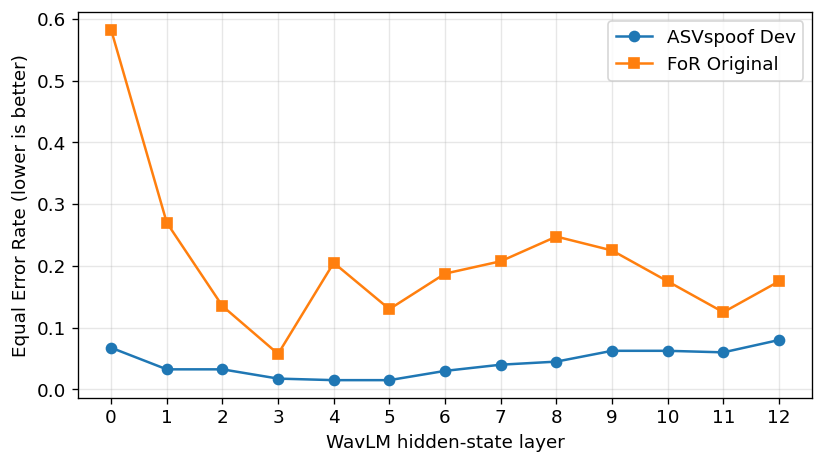


Best Dev layer: {'layer': 4, 'dev_eer': 0.015000000000000006, 'for_eer': 0.20499999999999996, 'dev_auc': 0.9972249999999999, 'for_auc': 0.87665}


In [ ]:
# Layer-wise probing
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

layer_results = []

for layer in range(Etr.shape[1]):
    X_train = Etr[:, layer, :]
    X_dev = EA[:, layer, :]
    X_for = EB[:, layer, :]

    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=SEED)
    )
    probe.fit(X_train, ytr)

    scores_dev = probe.predict_proba(X_dev)[:, 1]
    scores_for = probe.predict_proba(X_for)[:, 1]

    eer_dev = compute_eer(yA, scores_dev)
    eer_for = compute_eer(yB, scores_for)

    layer_results.append({
        "layer": layer,
        "dev_eer": eer_dev,
        "for_eer": eer_for,
        "dev_auc": roc_auc_score(yA, scores_dev),
        "for_auc": roc_auc_score(yB, scores_for),
    })

    print(
        f"Layer {layer:02d} | "
        f"Dev EER: {eer_dev:.4f} | FoR EER: {eer_for:.4f}"
    )

plt.figure(figsize=(7, 4))
layers = [r["layer"] for r in layer_results]
plt.plot(layers, [r["dev_eer"] for r in layer_results], marker="o", label="ASVspoof Dev")
plt.plot(layers, [r["for_eer"] for r in layer_results], marker="s", label="FoR Original")
plt.xlabel("WavLM hidden-state layer")
plt.ylabel("Equal Error Rate (lower is better)")
plt.xticks(layers)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figs/fig_layerwise_probe.png", dpi=200)
plt.show()

RESULTS["layerwise"] = layer_results
print("\nBest Dev layer:", min(layer_results, key=lambda r: r["dev_eer"]))

Trainable parameters: 782


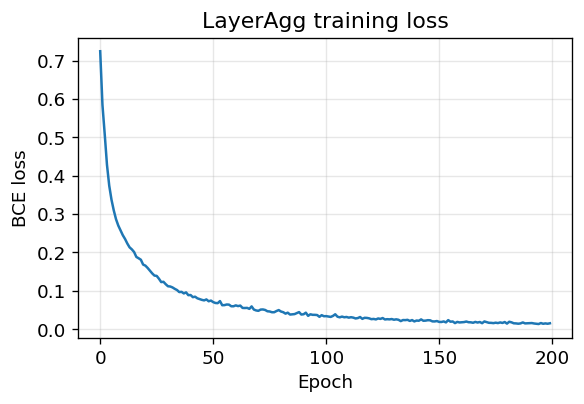

Learned layer weights: [0.052  0.0564 0.0949 0.1381 0.1609 0.1465 0.1031 0.0478 0.0404 0.0369
 0.0447 0.0402 0.0379]
Weight sum: 1.0


In [ ]:
# Train LayerAgg with training-only normalization
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

class LayerAgg(nn.Module):
    def __init__(self, L=13, D=768, p=0.2):
        super().__init__()
        self.w = nn.Parameter(torch.zeros(L))
        self.drop = nn.Dropout(p)
        self.head = nn.Linear(D, 1)

    def forward(self, x):
        a = torch.softmax(self.w, dim=0)
        z = (x * a[None, :, None]).sum(dim=1)
        return self.head(self.drop(z)).squeeze(-1)

# Fit normalization statistics on training data only
mu = Etr.mean(axis=0, keepdims=True)
sd = Etr.std(axis=0, keepdims=True) + 1e-6

def norm(E):
    return (E - mu) / sd

def train_agg(Xtr, ytr, epochs=200, lr=5e-3, wd=1e-2):
    torch.manual_seed(SEED)
    m = LayerAgg(Xtr.shape[1], Xtr.shape[2]).to(device)
    opt = torch.optim.AdamW(
        m.parameters(), lr=lr, weight_decay=wd
    )

    X = torch.as_tensor(norm(Xtr), dtype=torch.float32, device=device)
    y = torch.as_tensor(ytr, dtype=torch.float32, device=device)

    losses = []
    for ep in range(epochs):
        m.train()
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(m(X), y)
        loss.backward()
        opt.step()
        losses.append(loss.item())

    return m.eval(), losses

@torch.no_grad()
def agg_scores(m, E):
    X = torch.as_tensor(norm(E), dtype=torch.float32, device=device)
    m.eval()
    return m(X).cpu().numpy()

agg, losses = train_agg(Etr, ytr)

n_params = sum(p.numel() for p in agg.parameters())
print("Trainable parameters:", n_params)

plt.figure(figsize=(5, 3.5))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("LayerAgg training loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figs/fig_train_loss.png", dpi=200)
plt.show()

# Learned layer weights
layer_weights = torch.softmax(agg.w.detach().cpu(), dim=0).numpy()
print("Learned layer weights:", np.round(layer_weights, 4))
print("Weight sum:", layer_weights.sum())

RESULTS["trainable_params"] = n_params
RESULTS["layeragg_weights"] = layer_weights.tolist()

In [ ]:
# Evaluate LayerAgg on ASVspoof Dev and FoR
from sklearn.metrics import roc_auc_score
import numpy as np

scores_A = agg_scores(agg, EA)
scores_B = agg_scores(agg, EB)

eer_A = compute_eer(yA, scores_A)
eer_B = compute_eer(yB, scores_B)

auc_A = roc_auc_score(yA, scores_A)
auc_B = roc_auc_score(yB, scores_B)

print("=" * 45)
print("LayerAgg Evaluation")
print("=" * 45)
print(f"ASVspoof Dev | EER: {eer_A:.4f} ({eer_A*100:.2f}%) | AUC: {auc_A:.4f}")
print(f"FoR Original | EER: {eer_B:.4f} ({eer_B*100:.2f}%) | AUC: {auc_B:.4f}")

print("\nComparison with best single layer (Layer 4):")
best_layer = min(layer_results, key=lambda r: r["dev_eer"])
print(f"Single Layer 4 | Dev EER: {best_layer['dev_eer']:.4f} | FoR EER: {best_layer['for_eer']:.4f}")
print(f"LayerAgg       | Dev EER: {eer_A:.4f} | FoR EER: {eer_B:.4f}")

RESULTS["layeragg"] = {
    "dev_eer": float(eer_A),
    "for_eer": float(eer_B),
    "dev_auc": float(auc_A),
    "for_auc": float(auc_B),
}

LayerAgg Evaluation
ASVspoof Dev | EER: 0.0050 (0.50%) | AUC: 0.9993
FoR Original | EER: 0.1350 (13.50%) | AUC: 0.9481

Comparison with best single layer (Layer 4):
Single Layer 4 | Dev EER: 0.0150 | FoR EER: 0.2050
LayerAgg       | Dev EER: 0.0050 | FoR EER: 0.1350


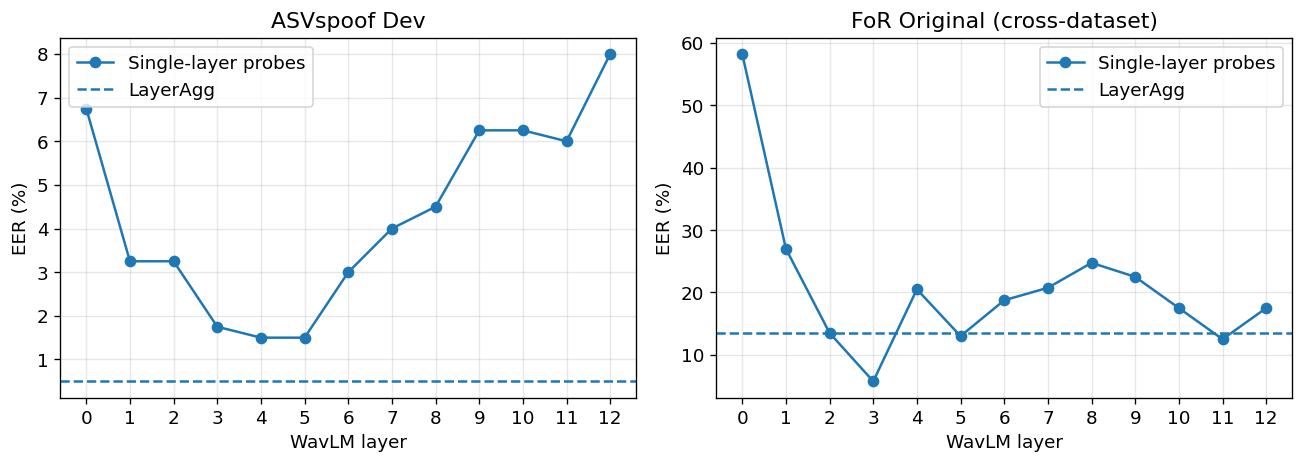

Saved: figs/fig_layeragg_comparison.png


In [ ]:
# Compare single-layer probing against LayerAgg
import matplotlib.pyplot as plt
import numpy as np

layers = [r["layer"] for r in layer_results]
dev_eers = [r["dev_eer"] * 100 for r in layer_results]
for_eers = [r["for_eer"] * 100 for r in layer_results]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(layers, dev_eers, marker="o", label="Single-layer probes")
axes[0].axhline(eer_A * 100, linestyle="--", label="LayerAgg")
axes[0].set_title("ASVspoof Dev")
axes[0].set_xlabel("WavLM layer")
axes[0].set_ylabel("EER (%)")
axes[0].set_xticks(layers)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(layers, for_eers, marker="o", label="Single-layer probes")
axes[1].axhline(eer_B * 100, linestyle="--", label="LayerAgg")
axes[1].set_title("FoR Original (cross-dataset)")
axes[1].set_xlabel("WavLM layer")
axes[1].set_ylabel("EER (%)")
axes[1].set_xticks(layers)
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig("figs/fig_layeragg_comparison.png", dpi=200)
plt.show()

print("Saved: figs/fig_layeragg_comparison.png")

Trainable parameters: 782


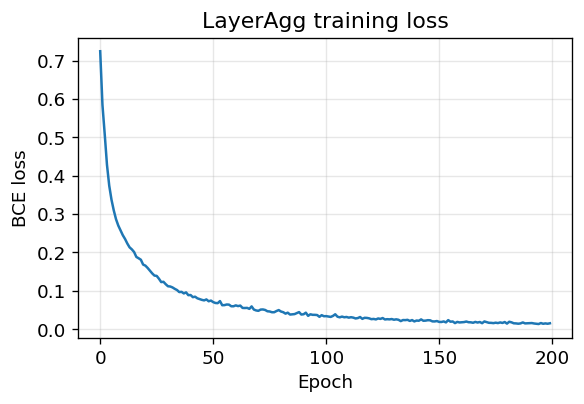

,Dataset,Method,EER,AUC,Accuracy
0,A (in-domain),Last layer + LR,0.080,0.9725,0.9150
1,A (in-domain),Best layer (4) + LR,0.015,0.9972,0.9900
2,A (in-domain),LayerAgg (ours),0.005,0.9993,0.9950
3,B (cross-dataset),Last layer + LR,0.175,0.9054,0.6350
4,B (cross-dataset),Best layer (4) + LR,0.205,0.8766,0.5500
5,B (cross-dataset),LayerAgg (ours),0.135,0.9480,0.7125


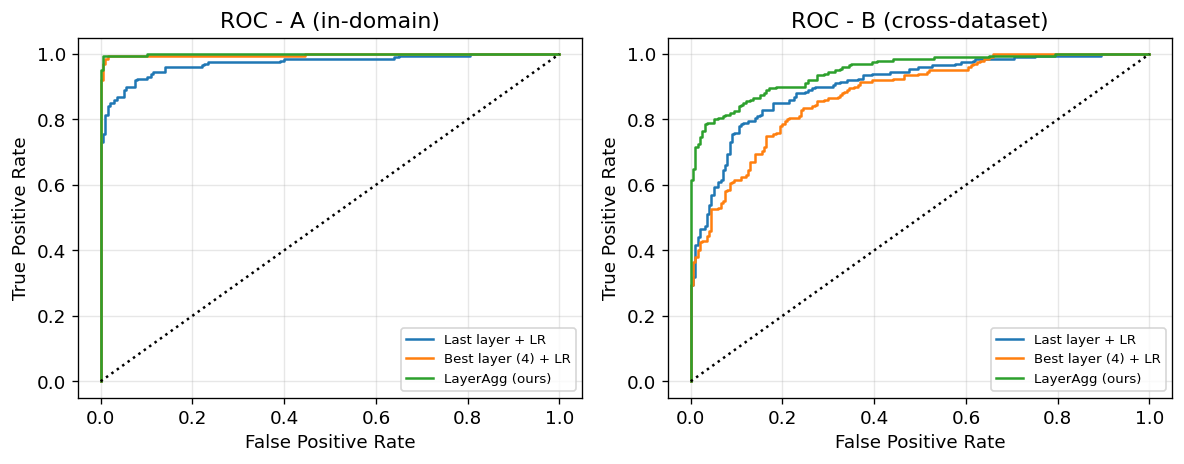

Saved: figs/fig_train_loss.png and figs/fig_roc.png


In [ ]:
# CELL: Train LayerAgg, compare baselines, and plot ROC curves
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve

# ---------- LayerAgg ----------
class LayerAgg(nn.Module):
    def __init__(self, L=13, D=768, p=0.2):
        super().__init__()
        self.w = nn.Parameter(torch.zeros(L))
        self.drop = nn.Dropout(p)
        self.head = nn.Linear(D, 1)

    def forward(self, x):
        a = torch.softmax(self.w, dim=0)
        z = (x * a[None, :, None]).sum(dim=1)
        return self.head(self.drop(z)).squeeze(-1)


# Normalize using training embeddings only
mu = Etr.mean(axis=0, keepdims=True)
sd = Etr.std(axis=0, keepdims=True) + 1e-6

def norm(E):
    return (E - mu) / sd


def train_agg(Xtr, ytr, epochs=200, lr=5e-3, wd=1e-2):
    torch.manual_seed(SEED)
    m = LayerAgg(Xtr.shape[1], Xtr.shape[2]).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)

    X = torch.as_tensor(norm(Xtr), dtype=torch.float32, device=device)
    y = torch.as_tensor(ytr, dtype=torch.float32, device=device)

    losses = []
    for _ in range(epochs):
        m.train()
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(m(X), y)
        loss.backward()
        opt.step()
        losses.append(loss.item())

    return m.eval(), losses


@torch.no_grad()
def agg_scores(m, E):
    X = torch.as_tensor(norm(E), dtype=torch.float32, device=device)
    m.eval()
    return m(X).cpu().numpy()


agg, losses = train_agg(Etr, ytr)
n_params = sum(p.numel() for p in agg.parameters())

print("Trainable parameters:", n_params)

plt.figure(figsize=(5, 3.5))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("LayerAgg training loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figs/fig_train_loss.png", dpi=200)
plt.show()

RESULTS["trainable_params"] = n_params


# ---------- Logistic regression baselines ----------
def fit_lr(X, y):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    clf = LogisticRegression(max_iter=1000, random_state=SEED)
    clf.fit(X_scaled, y)
    return scaler, clf


def lr_scores(scaler, clf, X):
    return clf.decision_function(scaler.transform(X))


best_layer = min(
    layer_results, key=lambda r: r["dev_eer"]
)["layer"]

sc_b, clf_b = fit_lr(Etr[:, best_layer, :], ytr)
sc_l, clf_l = fit_lr(Etr[:, -1, :], ytr)


def eval_all(E):
    return {
        "Last layer + LR": lr_scores(sc_l, clf_l, E[:, -1, :]),
        f"Best layer ({best_layer}) + LR": lr_scores(
            sc_b, clf_b, E[:, best_layer, :]
        ),
        "LayerAgg (ours)": agg_scores(agg, E),
    }


# ---------- Evaluation ----------
rows = []
roc_data = {}

for dname, E, y in [
    ("A (in-domain)", EA, yA),
    ("B (cross-dataset)", EB, yB),
]:
    for mname, scores in eval_all(E).items():
        rows.append({
            "Dataset": dname,
            "Method": mname,
            "EER": compute_eer(y, scores),
            "AUC": roc_auc_score(y, scores),
            "Accuracy": accuracy_score(y, scores > 0),
        })
        fpr, tpr, _ = roc_curve(y, scores)
        roc_data[(dname, mname)] = (fpr, tpr)

df_main = pd.DataFrame(rows).round(4)
display(df_main)
RESULTS["main"] = df_main.to_dict("records")


# ---------- ROC plots ----------
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

for ax, dname in zip(
    axs, ["A (in-domain)", "B (cross-dataset)"]
):
    for (dn, mn), (fpr, tpr) in roc_data.items():
        if dn == dname:
            ax.plot(fpr, tpr, label=mn)

    ax.plot([0, 1], [0, 1], "k:")
    ax.set_title(f"ROC - {dname}")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figs/fig_roc.png", dpi=200)
plt.show()

print("Saved: figs/fig_train_loss.png and figs/fig_roc.png")

,Dataset,Method,EER,AUC,Acc
0,A (in-domain),Last layer + LR,0.080,0.9725,0.9150
1,A (in-domain),Best layer (4) + LR,0.015,0.9972,0.9900
2,A (in-domain),LayerAgg (ours),0.005,0.9993,0.9950
3,B (cross-dataset),Last layer + LR,0.175,0.9054,0.6350
4,B (cross-dataset),Best layer (4) + LR,0.205,0.8766,0.5500
5,B (cross-dataset),LayerAgg (ours),0.135,0.9480,0.7125


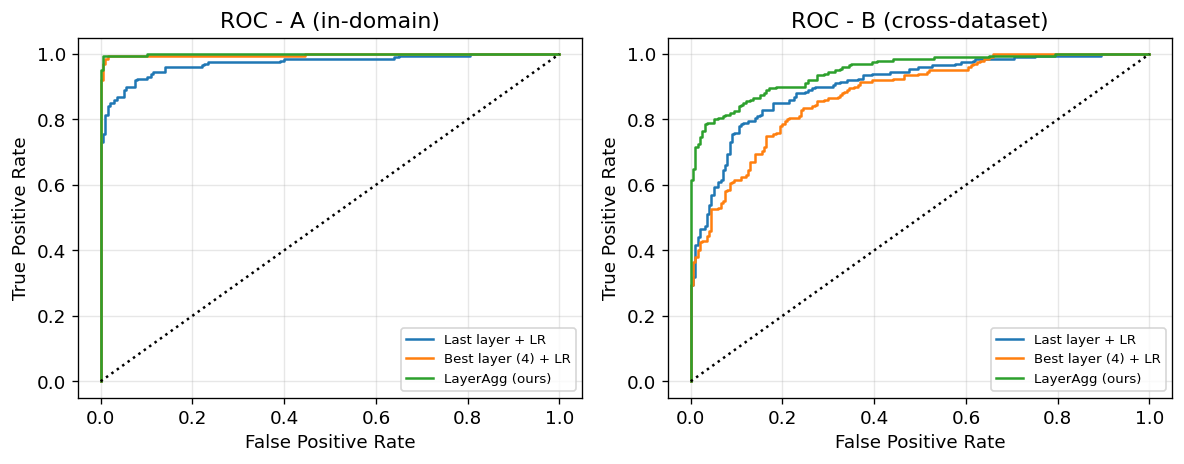

Saved: figs/fig_roc.png


In [ ]:
# Main evaluation (in-domain + cross-dataset)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve

# Fit baseline probes on training embeddings
sc_b, clf_b = fit_lr(Etr[:, best_layer, :], ytr)
sc_l, clf_l = fit_lr(Etr[:, -1, :], ytr)

def eval_all(E):
    out = {}
    out["Last layer + LR"] = lr_scores(sc_l, clf_l, E[:, -1, :])
    out[f"Best layer ({best_layer}) + LR"] = lr_scores(
        sc_b, clf_b, E[:, best_layer, :]
    )
    out["LayerAgg (ours)"] = agg_scores(agg, E)
    return out

rows, roc_data = [], {}

for dname, E, y in [
    ("A (in-domain)", EA, yA),
    ("B (cross-dataset)", EB, yB),
]:
    for mname, scores in eval_all(E).items():
        rows.append({
            "Dataset": dname,
            "Method": mname,
            "EER": compute_eer(y, scores),
            "AUC": roc_auc_score(y, scores),
            "Acc": accuracy_score(y, scores > 0),
        })

        fpr, tpr, _ = roc_curve(y, scores)
        roc_data[(dname, mname)] = (fpr, tpr)

df_main = pd.DataFrame(rows).round(4)
display(df_main)

RESULTS["main"] = df_main.to_dict("records")

# Plot ROC curves
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

for ax, dname in zip(
    axs, ["A (in-domain)", "B (cross-dataset)"]
):
    for (dn, mn), (fpr, tpr) in roc_data.items():
        if dn == dname:
            ax.plot(fpr, tpr, label=mn)

    ax.plot([0, 1], [0, 1], "k:")
    ax.set_title(f"ROC - {dname}")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figs/fig_roc.png", dpi=200)
plt.show()

print("Saved: figs/fig_roc.png")

## Robustness study
Test clips (dataset A) are corrupted with additive noise, 8 kHz resampling, mu-law 8-bit quantization and MP3 compression,
then re-embedded. Models are NOT retrained (train on clean only).

Processing: Clean
Done: Clean
Processing: Noise 20dB
Done: Noise 20dB
Processing: Noise 10dB
Done: Noise 10dB
Processing: Noise 0dB
Done: Noise 0dB
Processing: Resample 8k
Done: Resample 8k
Processing: Mu-law 8bit
Done: Mu-law 8bit
Processing: MP3 64k
Done: MP3 64k
Processing: MP3 32k
Done: MP3 32k


Method,Best layer (4) + LR,Last layer + LR,LayerAgg (ours)
Corruption,,,
Clean,0.0150,0.0800,0.0050
Noise 20dB,0.1175,0.2350,0.1100
Noise 10dB,0.1550,0.3050,0.2025
Noise 0dB,0.2750,0.3950,0.3525
Resample 8k,0.0150,0.0750,0.0100
Mu-law 8bit,0.0125,0.0825,0.0150
MP3 64k,0.0175,0.0800,0.0050
MP3 32k,0.0200,0.0675,0.0050


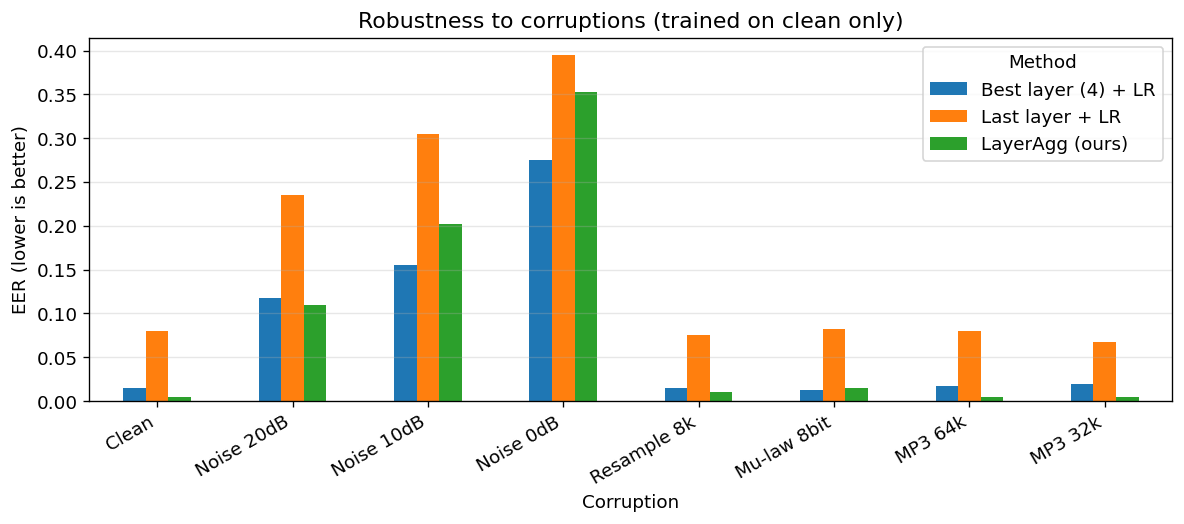

Saved: figs/fig_robustness.png


In [ ]:
# Robustness study — train on clean data only
import tempfile
import subprocess
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

def add_noise(w, snr):
    rng = np.random.RandomState(SEED)
    p = np.mean(np.asarray(w) ** 2) + 1e-12
    noise = rng.randn(len(w)) * np.sqrt(p / (10 ** (snr / 10)))
    return fix_len(np.asarray(w) + noise)

def lowres(w, sr=8000):
    x = librosa.resample(np.asarray(w), orig_sr=SR, target_sr=sr)
    x = librosa.resample(x, orig_sr=sr, target_sr=SR)
    return fix_len(x)

def mulaw8(w):
    w = np.asarray(w, dtype=np.float32)
    peak = np.max(np.abs(w)) + 1e-12
    x = np.clip(w / peak, -1.0, 1.0)
    q = librosa.mu_compress(x, mu=255, quantize=True)
    x = librosa.mu_expand(q, mu=255, quantize=True)
    return fix_len(x * peak)

def mp3(w, br="64k"):
    with tempfile.TemporaryDirectory() as d:
        wav_path = f"{d}/a.wav"
        mp3_path = f"{d}/a.mp3"

        sf.write(wav_path, np.asarray(w, dtype=np.float32), SR)

        subprocess.run(
            ["ffmpeg", "-y", "-loglevel", "error",
             "-i", wav_path, "-b:a", br, mp3_path],
            check=True,
            capture_output=True
        )

        x, _ = librosa.load(mp3_path, sr=SR, mono=True)

    return fix_len(x)

CORR = {
    "Clean": lambda w: w,
    "Noise 20dB": lambda w: add_noise(w, 20),
    "Noise 10dB": lambda w: add_noise(w, 10),
    "Noise 0dB": lambda w: add_noise(w, 0),
    "Resample 8k": lowres,
    "Mu-law 8bit": mulaw8,
    "MP3 64k": lambda w: mp3(w, "64k"),
    "MP3 32k": lambda w: mp3(w, "32k"),
}

rob_rows = []

for cname, fn in CORR.items():
    print(f"Processing: {cname}")

    Xc = [np.asarray(fn(w), dtype=np.float32) for w in XA_w]
    Ec = embed(Xc, bs=8)

    for mname, scores in eval_all(Ec).items():
        rob_rows.append({
            "Corruption": cname,
            "Method": mname,
            "EER": compute_eer(yA, scores),
        })

    print("Done:", cname)

df_rob = (
    pd.DataFrame(rob_rows)
    .pivot(index="Corruption", columns="Method", values="EER")
    .loc[list(CORR)]
    .round(4)
)

display(df_rob)
RESULTS["robustness"] = df_rob.reset_index().to_dict("records")

ax = df_rob.plot(kind="bar", figsize=(10, 4.5))
ax.set_ylabel("EER (lower is better)")
ax.set_title("Robustness to corruptions (trained on clean only)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("figs/fig_robustness.png", dpi=200)
plt.show()

print("Saved: figs/fig_robustness.png")

### Explainability
(1) Learned layer-importance weights, (2) t-SNE of embeddings, (3) temporal saliency via sliding-window scoring.

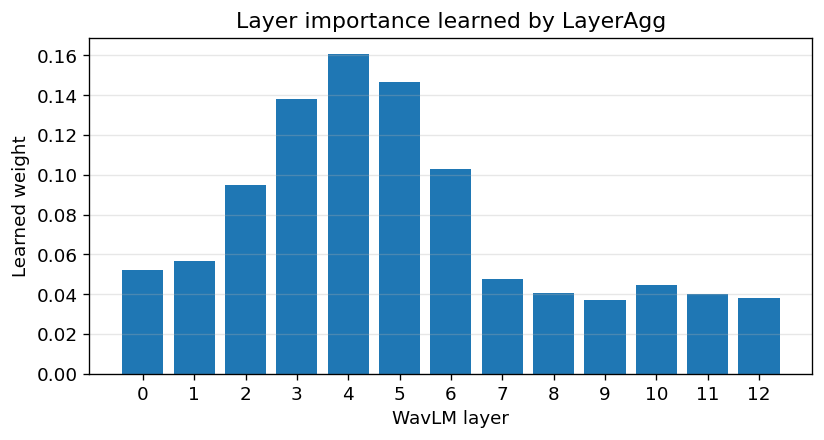

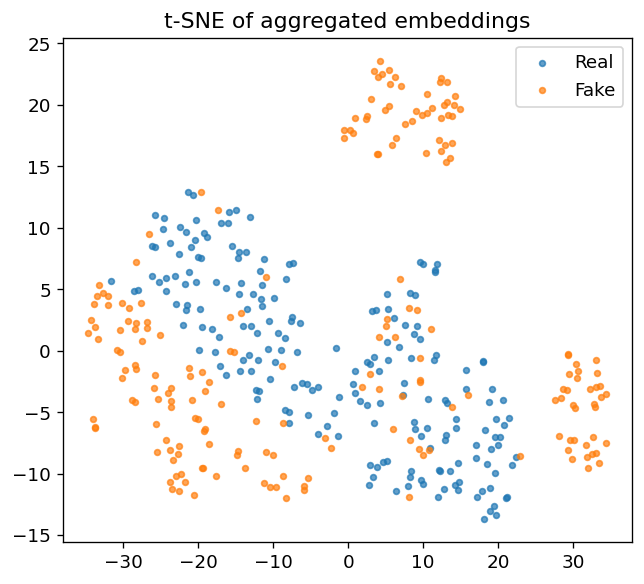

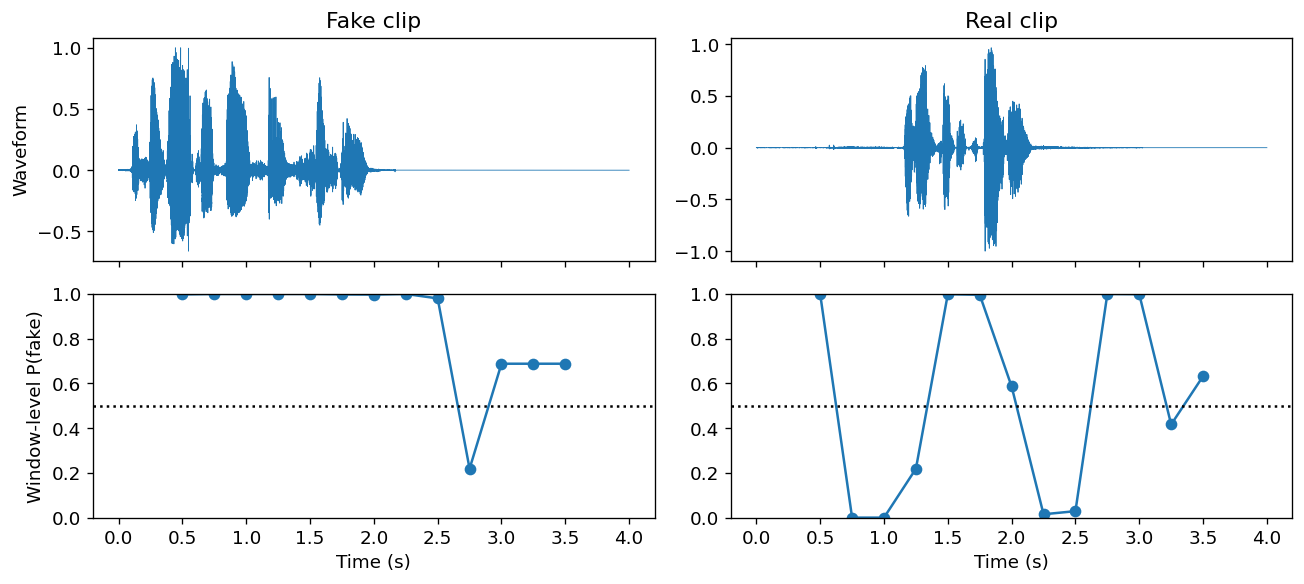

Saved explainability figures:
- figs/fig_layer_weights.png
- figs/fig_tsne.png
- figs/fig_temporal_saliency.png


In [ ]:
# Explainability — layer weights, t-SNE, and temporal saliency
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# (1) Learned layer importance weights
lw = torch.softmax(agg.w.detach().cpu(), dim=0).numpy()
L = len(lw)

plt.figure(figsize=(7, 3.8))
plt.bar(range(L), lw)
plt.xlabel("WavLM layer")
plt.ylabel("Learned weight")
plt.title("Layer importance learned by LayerAgg")
plt.xticks(range(L))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("figs/fig_layer_weights.png", dpi=200)
plt.show()

RESULTS["layer_weights"] = lw.tolist()


# (2) t-SNE of aggregated representations
a = lw.copy()
Z = (norm(EA) * a[None, :, None]).sum(axis=1)

Z2 = TSNE(
    n_components=2,
    perplexity=30,
    random_state=SEED,
    init="pca",
    learning_rate="auto"
).fit_transform(Z)

plt.figure(figsize=(5.5, 5))
plt.scatter(
    Z2[yA == 0, 0], Z2[yA == 0, 1],
    s=12, label="Real", alpha=0.7
)
plt.scatter(
    Z2[yA == 1, 0], Z2[yA == 1, 1],
    s=12, label="Fake", alpha=0.7
)
plt.legend()
plt.title("t-SNE of aggregated embeddings")
plt.tight_layout()
plt.savefig("figs/fig_tsne.png", dpi=200)
plt.show()


# (3) Temporal saliency: score one-second windows, 0.25-second hop
def temporal_scores(w, win=SR, hop=SR // 4):
    w = np.asarray(w, dtype=np.float32)
    starts = list(range(0, len(w) - win + 1, hop))

    if not starts:
        raise ValueError("Audio is shorter than the analysis window.")

    segs = [w[s:s + win] for s in starts]
    E = embed(segs, bs=16)
    scores = agg_scores(agg, E)

    times = np.asarray(starts) / SR + win / (2 * SR)
    return times, scores


fake_idx = np.where(yA == 1)[0][0]
real_idx = np.where(yA == 0)[0][0]

fig, axs = plt.subplots(2, 2, figsize=(11, 5), sharex="col")

for col, (name, i) in enumerate([
    ("Fake clip", fake_idx),
    ("Real clip", real_idx)
]):
    w = XA_w[i]
    t, s = temporal_scores(w)

    axs[0, col].plot(np.arange(len(w)) / SR, w, lw=0.5)
    axs[0, col].set_title(name)

    # Convert logits to probabilities
    prob = 1 / (1 + np.exp(-np.clip(s, -50, 50)))
    axs[1, col].plot(t, prob, "o-")
    axs[1, col].axhline(0.5, color="k", ls=":")
    axs[1, col].set_ylim(0, 1)
    axs[1, col].set_xlabel("Time (s)")

axs[0, 0].set_ylabel("Waveform")
axs[1, 0].set_ylabel("Window-level P(fake)")
plt.tight_layout()
plt.savefig("figs/fig_temporal_saliency.png", dpi=200)
plt.show()

print("Saved explainability figures:")
print("- figs/fig_layer_weights.png")
print("- figs/fig_tsne.png")
print("- figs/fig_temporal_saliency.png")

In [ ]:
# CELL 17: Save results and download package
import json
import os
import subprocess
from pathlib import Path
from google.colab import files

os.makedirs("figs", exist_ok=True)

# Save complete results
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)

# Save evaluation tables
df_main.to_csv("results_main.csv", index=False)
df_rob.to_csv("results_robustness.csv")

# Package figures and result files
result = subprocess.run(
    [
        "zip", "-qr", "results_package.zip",
        "figs",
        "results.json",
        "results_main.csv",
        "results_robustness.csv",
    ],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(result.stderr)

print("Package created:", Path("results_package.zip").stat().st_size, "bytes")
files.download("results_package.zip")

Package created: 641330 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# CELL 18: Final experiment summary
import json

summary_keys = [
    "data",
    "trainable_params",
    "main",
    "robustness",
    "layer_weights",
]

summary = {
    key: RESULTS[key]
    for key in summary_keys
    if key in RESULTS
}

print(json.dumps(summary, indent=2, default=float))

best_layer_result = min(
    layer_results,
    key=lambda r: r["dev_eer"]
)

print("\nBest layer:", best_layer_result["layer"])
print("Best Dev EER:", best_layer_result["dev_eer"])
print("Corresponding FoR EER:", best_layer_result["for_eer"])

print("\nGenerated figures:")
for path in sorted(Path("figs").glob("*.png")):
    print(path)

{
  "trainable_params": 782,
  "main": [
    {
      "Dataset": "A (in-domain)",
      "Method": "Last layer + LR",
      "EER": 0.08,
      "AUC": 0.9725,
      "Acc": 0.915
    },
    {
      "Dataset": "A (in-domain)",
      "Method": "Best layer (4) + LR",
      "EER": 0.015,
      "AUC": 0.9972,
      "Acc": 0.99
    },
    {
      "Dataset": "A (in-domain)",
      "Method": "LayerAgg (ours)",
      "EER": 0.005,
      "AUC": 0.9993,
      "Acc": 0.995
    },
    {
      "Dataset": "B (cross-dataset)",
      "Method": "Last layer + LR",
      "EER": 0.175,
      "AUC": 0.9054,
      "Acc": 0.635
    },
    {
      "Dataset": "B (cross-dataset)",
      "Method": "Best layer (4) + LR",
      "EER": 0.205,
      "AUC": 0.8766,
      "Acc": 0.55
    },
    {
      "Dataset": "B (cross-dataset)",
      "Method": "LayerAgg (ours)",
      "EER": 0.135,
      "AUC": 0.948,
      "Acc": 0.7125
    }
  ],
  "robustness": [
    {
      "Corruption": "Clean",
      "Best layer (4) + LR": 0.01

In [ ]:
# Extract official ASVspoof evaluation protocol
import subprocess
from pathlib import Path

archive = "/content/ASVspoof2019_archives/ASVspoof2019.7z.001"
out_dir = Path("/content/asvspoof_protocols")
out_dir.mkdir(parents=True, exist_ok=True)

target = (
    "ASVspoof2019/Original/ASVspoof2019_LA_cm_protocols/"
    "ASVspoof2019.LA.cm.eval.trl.txt"
)

result = subprocess.run(
    ["7z", "e", "-y", f"-o{out_dir}", archive, target],
    capture_output=True,
    text=True,
    timeout=600
)

print("Return code:", result.returncode)
if result.returncode != 0:
    print(result.stderr[-3000:])
else:
    eval_file = out_dir / "ASVspoof2019.LA.cm.eval.trl.txt"
    print("Protocol exists:", eval_file.exists())
    if eval_file.exists():
        print("File size:", f"{eval_file.stat().st_size:,}", "bytes")
        with open(eval_file) as f:
            for _ in range(5):
                print(f.readline().strip())

Return code: 0
Protocol exists: True
File size: 2,358,176 bytes
LA_0039 LA_E_2834763 - A11 spoof
LA_0014 LA_E_8877452 - A14 spoof
LA_0040 LA_E_6828287 - A16 spoof
LA_0022 LA_E_6977360 - A09 spoof
LA_0031 LA_E_5932896 - A13 spoof


In [ ]:
# CELL 20: Select balanced official evaluation samples
from pathlib import Path
from collections import Counter
import random
import subprocess

random.seed(SEED)

eval_file = Path("/content/asvspoof_protocols/ASVspoof2019.LA.cm.eval.trl.txt")
eval_rows = []

with open(eval_file, "r") as f:
    for line in f:
        parts = line.split()
        if len(parts) >= 5 and parts[-1] in ("bonafide", "spoof"):
            eval_rows.append({
                "utt_id": parts[1],
                "label": 0 if parts[-1] == "bonafide" else 1,
                "split": "eval",
                "path": (
                    "ASVspoof2019/Original/"
                    f"ASVspoof2019_LA_eval/flac/{parts[1]}.flac"
                )
            })

print("Official eval labels:", Counter(r["label"] for r in eval_rows))

selected_eval = []
for label in (0, 1):
    candidates = [r for r in eval_rows if r["label"] == label]
    selected_eval.extend(random.sample(candidates, min(200, len(candidates))))

random.shuffle(selected_eval)

print("Selected:", len(selected_eval))
print("Selected labels:", Counter(r["label"] for r in selected_eval))

# Extract selected files only
archive = "/content/ASVspoof2019_archives/ASVspoof2019.7z.001"
out_dir = Path("/content/asvspoof_selected")
out_dir.mkdir(parents=True, exist_ok=True)

targets = [r["path"] for r in selected_eval]
failed_batches = []

for start in range(0, len(targets), 50):
    batch = targets[start:start + 50]
    result = subprocess.run(
        ["7z", "x", "-y", f"-o{out_dir}", archive, *batch],
        capture_output=True,
        text=True,
        timeout=1800
    )

    if result.returncode != 0:
        failed_batches.append((start, result.stderr[-1000:]))

    print(f"Processed {min(start + 50, len(targets))}/{len(targets)}")

audio_root = out_dir / "ASVspoof2019" / "Original"
eval_audio_map = {p.stem: p for p in audio_root.rglob("*.flac")}

missing_eval = [
    r["utt_id"] for r in selected_eval
    if r["utt_id"] not in eval_audio_map
]

print("\nExtracted audio files:", len(eval_audio_map))
print("Missing eval files:", len(missing_eval))
print("Failed batches:", len(failed_batches))
print("Example missing IDs:", missing_eval[:10])

Official eval labels: Counter({1: 63882, 0: 7355})
Selected: 400
Selected labels: Counter({0: 200, 1: 200})
Processed 50/400
Processed 100/400
Processed 150/400
Processed 200/400
Processed 250/400
Processed 300/400
Processed 350/400
Processed 400/400

Extracted audio files: 1600
Missing eval files: 0
Failed batches: 0
Example missing IDs: []


In [ ]:
# CELL 21: Load official evaluation audio and evaluate existing models
Xeval_w, yeval, missing_eval_load = load_asvspoof_rows(
    selected_eval, eval_audio_map
)

print("Evaluation waveforms:", len(Xeval_w))
print("Labels:", Counter(yeval.tolist()))
print("Missing:", len(missing_eval_load))

Eeval = embed(Xeval_w, bs=8)

eval_rows = []
for method, scores in eval_all(Eeval).items():
    eval_rows.append({
        "Dataset": "Official ASVspoof Eval",
        "Method": method,
        "EER": compute_eer(yeval, scores),
        "AUC": roc_auc_score(yeval, scores),
        "Accuracy": accuracy_score(yeval, scores > 0),
    })

df_official_eval = pd.DataFrame(eval_rows).round(4)
display(df_official_eval)

RESULTS["official_eval"] = df_official_eval.to_dict("records")
df_official_eval.to_csv("results_official_eval.csv", index=False)

Loading eval audio:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluation waveforms: 400
Labels: Counter({0: 200, 1: 200})
Missing: 0


,Dataset,Method,EER,AUC,Accuracy
0,Official ASVspoof Eval,Last layer + LR,0.0400,0.9767,0.9600
1,Official ASVspoof Eval,Best layer (4) + LR,0.0275,0.9904,0.9475
2,Official ASVspoof Eval,LayerAgg (ours),0.0125,0.9988,0.9725


In [ ]:
# CELL 21: Evaluate models on held-out ASVspoof samples

Xeval_w, yeval, missing_eval_load = load_asvspoof_rows(
    selected_eval, eval_audio_map
)

print("Evaluation waveforms:", len(Xeval_w))
print("Labels:", Counter(yeval.tolist()))
print("Missing:", len(missing_eval_load))

Eeval = embed(Xeval_w, bs=8)

eval_rows = []
for method, scores in eval_all(Eeval).items():
    eval_rows.append({
        "Dataset": "Official ASVspoof Eval (400-sample subset)",
        "Method": method,
        "EER": compute_eer(yeval, scores),
        "AUC": roc_auc_score(yeval, scores),
        "Accuracy": accuracy_score(yeval, scores > 0),
    })

df_official_eval = pd.DataFrame(eval_rows).round(4)
display(df_official_eval)

RESULTS["official_eval"] = df_official_eval.to_dict("records")
df_official_eval.to_csv("results_official_eval.csv", index=False)

Loading eval audio:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluation waveforms: 400
Labels: Counter({0: 200, 1: 200})
Missing: 0


,Dataset,Method,EER,AUC,Accuracy
0,Official ASVspoof Eval (400-sample subset),Last layer + LR,0.0400,0.9767,0.9600
1,Official ASVspoof Eval (400-sample subset),Best layer (4) + LR,0.0275,0.9904,0.9475
2,Official ASVspoof Eval (400-sample subset),LayerAgg (ours),0.0125,0.9988,0.9725


In [ ]:
# Verify Main Results and Correct Table I Formatting

import pandas as pd
from IPython.display import display, HTML

# Check stored main results
df_check = pd.DataFrame(RESULTS["main"])

print("Main results available:")
display(df_check)

# Verify evaluation subset results
if "official_eval" in RESULTS:
    print("\nOfficial ASVspoof Evaluation Subset:")
    display(pd.DataFrame(RESULTS["official_eval"]))
else:
    print("\nOfficial evaluation results not found in RESULTS.")

# Build a formatted Table I using the stored results
expected_datasets = [
    "ASVspoof Dev",
    "Official ASVspoof Eval (400-sample subset)",
    "FoR"
]

df_main_check = pd.DataFrame(RESULTS["main"]).copy()

# Normalize dataset labels for display
print("\nCheck exact dataset and method names before final report:")
print(df_main_check[["Dataset", "Method", "EER", "AUC", "Acc"]].to_string(index=False))

# Correct bolding: best EER = minimum; best AUC and accuracy = maximum
def bold_best_values(group):
    best_eer = group["EER"].min()
    best_auc = group["AUC"].max()
    best_acc = group["Acc"].max()

    def fmt(value, best, higher_is_better=False):
        return f"<b>{value:.4f}</b>" if abs(value - best) < 1e-9 else f"{value:.4f}"

    rows = []
    for _, row in group.iterrows():
        rows.append({
            "Method": row["Method"],
            "EER": fmt(row["EER"], best_eer),
            "AUC": fmt(row["AUC"], best_auc),
            "Accuracy": fmt(row["Acc"], best_acc),
        })
    return rows

for dataset in df_main_check["Dataset"].unique():
    group = df_main_check[df_main_check["Dataset"] == dataset]
    print(f"\n{dataset}")
    display(HTML(pd.DataFrame(bold_best_values(group)).to_html(
        index=False, escape=False
    )))

Main results available:


,Dataset,Method,EER,AUC,Acc
0,A (in-domain),Last layer + LR,0.080,0.9725,0.9150
1,A (in-domain),Best layer (4) + LR,0.015,0.9972,0.9900
2,A (in-domain),LayerAgg (ours),0.005,0.9993,0.9950
3,B (cross-dataset),Last layer + LR,0.175,0.9054,0.6350
4,B (cross-dataset),Best layer (4) + LR,0.205,0.8766,0.5500
5,B (cross-dataset),LayerAgg (ours),0.135,0.9480,0.7125



Official ASVspoof Evaluation Subset:


,Dataset,Method,EER,AUC,Accuracy
0,Official ASVspoof Eval (400-sample subset),Last layer + LR,0.0400,0.9767,0.9600
1,Official ASVspoof Eval (400-sample subset),Best layer (4) + LR,0.0275,0.9904,0.9475
2,Official ASVspoof Eval (400-sample subset),LayerAgg (ours),0.0125,0.9988,0.9725



Check exact dataset and method names before final report:
          Dataset              Method   EER    AUC    Acc
    A (in-domain)     Last layer + LR 0.080 0.9725 0.9150
    A (in-domain) Best layer (4) + LR 0.015 0.9972 0.9900
    A (in-domain)     LayerAgg (ours) 0.005 0.9993 0.9950
B (cross-dataset)     Last layer + LR 0.175 0.9054 0.6350
B (cross-dataset) Best layer (4) + LR 0.205 0.8766 0.5500
B (cross-dataset)     LayerAgg (ours) 0.135 0.9480 0.7125

A (in-domain)


Method,EER,AUC,Accuracy
Last layer + LR,0.0800,0.9725,0.9150
Best layer (4) + LR,0.0150,0.9972,0.9900
LayerAgg (ours),0.0050,0.9993,0.9950



B (cross-dataset)


Method,EER,AUC,Accuracy
Last layer + LR,0.1750,0.9054,0.6350
Best layer (4) + LR,0.2050,0.8766,0.5500
LayerAgg (ours),0.1350,0.9480,0.7125
